### 1. Coherent baseline results

In [10]:
# 1 — Fixed settings. Use the existing .venv-scgpt kernel on Nibi.
from pathlib import Path
from datetime import datetime, timezone
import gc, gzip, hashlib, importlib.util, importlib.metadata, json, platform, sys, time
import numpy as np
import pandas as pd
import anndata as ad
from scipy import sparse
from scipy.io import mmread
from threadpoolctl import threadpool_limits
import torch
from IPython.display import display

ROOT = Path.home() / "scgpt-cna"
LAB_ROOT = Path("/home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/benchmarking_spatial_scale")
META = LAB_ROOT / "metadata/sample_md.tsv"
GDC_ROOT = LAB_ROOT / "GDC-data"
MODEL = ROOT / "models/whole-human"
HELPER = ROOT / "notebooks/scgpt_session/scgpt_session.py"
HISTORICAL = ROOT / "sanity_check/reference_4068d67/scgpt"
DATA = CENSUS_ANNOTATION = ROOT / "sanity_check/data/census_proximal_tubule_256/reference_raw.h5ad"
COHORT_ID = "CENSUS_PROXIMAL_TUBULE_256"
SAMPLE_IDS = ["C3N-00148-01", "C3L-00359-01", "C3L-01287-01",
              "C3L-03405-01", "C3N-01798-01", "C3N-01816-01"]
MODE = "full" 
assert MODE in {"pilot", "full"}
ACTIVE_SAMPLE_IDS = SAMPLE_IDS[:1] if MODE == "pilot" else SAMPLE_IDS
N_REFERENCE = N_EVALUATION = 128
MAX_EVALUATED = 8 if MODE == "pilot" else 128
SPLIT_SEED = 42
MASK_SEEDS = [42] if MODE == "pilot" else [42,43,44,45]
MASK_FRACTION = .25
RUN_SHUFFLED = True
N_THREADS = 4
BOOTSTRAPS = 2000
MATRIX_DIR_OVERRIDES = {}
COPYKAT_OVERRIDES = {}
# Optional explicit old run directories for a specimen. All compatibility checks still apply.
REUSE_OVERRIDES = {}  # {"C3N-00148-01": Path("...timestamp_full/C3N-00148-01")}
REUSE_SAVED = True
METHODS = ["GEP", "MVC", "gene_mean_plus_offset", "gene_mean", "visible_mean",
           "reference_constant", "GEP_shuffled", "MVC_shuffled"]
HEADS = ["GEP", "MVC"]
BASELINE = "gene_mean_plus_offset"
COUNT_GROUPS = ["1 UMI", "2–4 UMIs", "5+ UMIs", "all"]
RESULTS_ROOT = ROOT / "report_benchmark/results"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + MODE
RUN_DIR = RESULTS_ROOT / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
for path in [META, DATA, HELPER, HISTORICAL/"preprocess.py", HISTORICAL/"data_collator.py",
             MODEL/"args.json", MODEL/"vocab.json", MODEL/"best_model.pt"]:
    assert path.is_file(), f"Missing required existing file: {path}"
torch.set_num_threads(N_THREADS)
print("Python:", sys.executable, "| torch:", torch.__version__)
print("Mode:", MODE, "| evaluated per unit:", MAX_EVALUATED, "| masks:", MASK_SEEDS)
print("Output:", RUN_DIR)


Python: /home/akash1/scgpt-cna/.venv-scgpt/bin/python | torch: 2.2.2+cpu
Mode: full | evaluated per unit: 128 | masks: [42, 43, 44, 45]
Output: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full


In [11]:
# 2 — Pin representation and hashes. The model is loaded lazily only if inference is needed.
def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(8*1024**2), b""):
            h.update(block)
    return h.hexdigest()

def import_file(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    assert Path(module.__file__).resolve() == Path(path).resolve()
    return module

config = json.loads((MODEL/"args.json").read_text())
vocab = json.loads((MODEL/"vocab.json").read_text())
assert isinstance(vocab, dict)
assert config["n_bins"] == 51 and config["max_seq_len"] == 1200
assert config["input_style"] == "binned" and config["input_emb_style"] == "continuous"
assert config["USE_GENERATIVE_TRAINING"] and config["MVC"]
historical = import_file("report_historical_preprocess", HISTORICAL/"preprocess.py")
historical_collator = import_file("scgpt._report_historical_collator", HISTORICAL/"data_collator.py")
historical_collator.binning = historical.binning
assert historical._digitize.__defaults__ == ("one",)
pad_id, cls_id = vocab[config.get("pad_token", "<pad>")], vocab["<cls>"]
pad_value = config.get("pad_value", -2)
collator = historical_collator.DataCollator(
    do_padding=True, pad_token_id=pad_id, pad_value=pad_value, do_mlm=True, do_binning=True,
    mlm_probability=MASK_FRACTION, mask_value=config.get("mask_value", -1),
    max_length=1200, sampling=True, keep_first_n_tokens=1, data_style="both")
HASHES = {"checkpoint_sha256": sha256(MODEL/"best_model.pt"), "vocab_sha256": sha256(MODEL/"vocab.json"),
          "helper_sha256": sha256(HELPER), "historical_preprocess_sha256": sha256(HISTORICAL/"preprocess.py"),
          "historical_collator_sha256": sha256(HISTORICAL/"data_collator.py")}
model = None

def ensure_model():
    global model
    if model is None:
        session = import_file("report_verified_session", HELPER)
        model, loaded_vocab, loaded_config = session.load_model(MODEL)
        assert loaded_config == config and loaded_vocab.get_stoi() == vocab
        model = model.cpu().eval()
    return model

run_manifest = {"run_id":RUN_ID, "mode":MODE, "sample_ids":ACTIVE_SAMPLE_IDS+[COHORT_ID],
    "n_reference":128, "n_evaluation_reserved":128, "n_evaluated":MAX_EVALUATED,
    "split_seed":SPLIT_SEED, "mask_seeds":MASK_SEEDS, "mask_fraction":MASK_FRACTION,
    "run_shuffled":True, "config":config, **HASHES,
    "historical_commit":"4068d67caaac1e28d56964da68e0214817e38428",
    "census_data_sha256":sha256(DATA), "census_annotation_path":str(DATA),
    "primary_head":"GEP", "secondary_head":"MVC", "baseline":BASELINE,
    "versions":{p:importlib.metadata.version(p) for p in ["torch","scgpt","anndata","numpy","scipy","pandas"]},
    "python":sys.version, "platform":platform.platform(),
    "eligibility":"At least 4 detected model genes; no new biological QC threshold",
    "status":"Exploratory already-inspected populations; independent validation cohort pending",
    "limitations":["Detected-gene bin reconstruction only; full-profile bins use hidden values",
                   "Within-specimen/cohort reference adaptation; Census donors may overlap splits",
                   "Census healthy-donor status and checkpoint training membership unconfirmed",
                   "Cell bootstrap intervals do not quantify patient-population uncertainty"]}
(RUN_DIR/"run_manifest.json").write_text(json.dumps(run_manifest, indent=2))
print("Historical representation verified; model weights not loaded yet.")


Historical representation verified; model weights not loaded yet.


In [12]:
# 3 — Verify data identities, record source provenance and preview Census annotations.
metadata = pd.read_csv(META, sep="\t", dtype=str)
assert metadata["sample_id"].is_unique
missing = set(ACTIVE_SAMPLE_IDS) - set(metadata["sample_id"])
assert not missing, f"IDs absent from sample metadata: {sorted(missing)}"
selected_metadata = metadata.set_index("sample_id").loc[ACTIVE_SAMPLE_IDS].reset_index()
assert selected_metadata["case_id"].is_unique, "Choose one specimen per patient initially."

def sidecar(directory, stem):
    candidates = [directory / stem, directory / (stem + ".gz")]
    found = [p for p in candidates if p.is_file()]
    assert len(found) == 1, f"Expected one {stem}(.gz) in {directory}; found {found}"
    return found[0]

def discover_sample(record):
    sid, case = record["sample_id"], record["case_id"]
    sample_dir = GDC_ROOT / case / sid
    assert sample_dir.is_dir(), f"Missing sample directory: {sample_dir}"
    if sid in MATRIX_DIR_OVERRIDES:
        matrix_dir = Path(MATRIX_DIR_OVERRIDES[sid])
    else:
        # Search only this specimen's single_cell subtree; ignore dense CSVs/archives.
        candidates = sorted({p.parent for p in (sample_dir / "single_cell").rglob("matrix.mtx*")
                             if p.name in {"matrix.mtx", "matrix.mtx.gz"}})
        filtered = [p for p in candidates if "filtered" in str(p).lower()
                    and "raw_feature" not in str(p).lower()]
        if filtered:
            candidates = filtered
        assert len(candidates) == 1, (
            f"Ambiguous/missing MEX directory for {sid}: {candidates}. "
            "Set MATRIX_DIR_OVERRIDES explicitly. Do not choose a raw droplet matrix."
        )
        matrix_dir = candidates[0]
    ck = ([Path(COPYKAT_OVERRIDES[sid])] if sid in COPYKAT_OVERRIDES else
          sorted((sample_dir / "single_cell").rglob("*copykat_prediction.txt")))
    assert len(ck) <= 1, f"Multiple CopyKAT files for {sid}; set COPYKAT_OVERRIDES."
    if ck:
        assert ck[0].is_file()
    return {
        **record, "sample_directory": str(sample_dir),
        "matrix_file": str(sidecar(matrix_dir, "matrix.mtx")),
        "features_file": str(sidecar(matrix_dir, "features.tsv")),
        "barcodes_file": str(sidecar(matrix_dir, "barcodes.tsv")),
        "copykat_file": str(ck[0]) if ck else "",
    }

manifest = pd.DataFrame([discover_sample(r) for r in selected_metadata.to_dict("records")])
display(manifest[["case_id", "sample_id", "primary_site",
                  "diagnoses.0.primary_diagnosis", "wgd_status", "matrix_file"]])
manifest.to_csv(RUN_DIR / "sample_manifest.tsv", sep="\t", index=False)
print("All selected specimens have an unambiguous sparse matrix.")

manifest["source"] = "Lab"
manifest["evaluation_unit"] = "specimen"
assert len(manifest) == len(ACTIVE_SAMPLE_IDS)
for sid in ACTIVE_SAMPLE_IDS:
    row = manifest.loc[manifest.sample_id.eq(sid)].iloc[0]
    expected = "Brain" if sid in SAMPLE_IDS[3:] else "Kidney"
    assert row.primary_site == expected, f"Unexpected tissue metadata for {sid}"
preview = ad.read_h5ad(DATA, backed="r")
assert preview.n_obs == 256 and "counts" in preview.layers
required_obs = {"soma_joinid", "donor_id", "cell_type", "dataset_id", "assay", "disease"}
assert required_obs.issubset(preview.obs)
assert preview.obs.soma_joinid.is_unique
assert preview.obs.cell_type.astype(str).str.contains("proximal", case=False).all()
print("Census source annotations (NOT a verified healthy-donor control):")
display(preview.obs.groupby(["dataset_id","cell_type","assay","disease"], observed=True).size().rename("n_cells").reset_index())
display(preview.obs.donor_id.value_counts(dropna=False).rename("n_cells"))
preview.obs.to_csv(RUN_DIR/"census_source_cell_annotations.tsv", sep="\t")
(RUN_DIR/"census_source_manifest.json").write_text(json.dumps(preview.uns.get("source_manifest",{}), indent=2, default=str))
preview.file.close()
del preview
census_record = {"sample_id":COHORT_ID, "case_id":"not_applicable", "primary_site":"Kidney",
    "diagnoses.0.primary_diagnosis":"Census-annotated proximal-tubule cohort", "wgd_status":"not_available",
    "source":"Census", "evaluation_unit":"pooled-donor cohort", "source_h5ad":str(DATA)}
manifest = pd.concat([manifest, pd.DataFrame([census_record])], ignore_index=True)
manifest.to_csv(RUN_DIR/"evaluation_units.tsv", sep="\t", index=False)
print("Data sources verified. This notebook does not infer cell types or malignancy.")


,case_id,sample_id,primary_site,diagnoses.0.primary_diagnosis,wgd_status,matrix_file
0,C3N-00148,C3N-00148-01,Kidney,"Renal cell carcinoma, NOS",WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
1,C3L-00359,C3L-00359-01,Kidney,"Renal cell carcinoma, NOS",WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
2,C3L-01287,C3L-01287-01,Kidney,"Renal cell carcinoma, NOS",WGD-,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
3,C3L-03405,C3L-03405-01,Brain,Glioblastoma,WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
4,C3N-01798,C3N-01798-01,Brain,Glioblastoma,WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...
5,C3N-01816,C3N-01816-01,Brain,Glioblastoma,WGD-,/home/akash1/projects/rrg-tperkins/dgladish/Pr...


All selected specimens have an unambiguous sparse matrix.
Census source annotations (NOT a verified healthy-donor control):


,dataset_id,cell_type,assay,disease,n_cells
0,9ea768a2-87ab-46b6-a73d-c4e915f25af3,epithelial cell of proximal tubule,10x 3' v2,normal,256


donor_id
TTx       118
VHL        26
RCC3       23
Wilms1     19
RCC2       18
TxK4       18
Wilms3     16
TxK1       13
RCC1        3
TxK2        1
Wilms2      1
Name: n_cells, dtype: int64

Data sources verified. This notebook does not infer cell types or malignancy.


In [13]:
# 5 — Independent reference cells, native-bin baselines and verified model inputs.
COUNT_GROUPS = ["1 UMI", "2–4 UMIs", "5+ UMIs", "all"]

def umi_groups(values):
    return np.select([values == 1, values <= 4], COUNT_GROUPS[:2], default=COUNT_GROUPS[2])

def reserve_cells(obs):
    minimum_genes = max(2, int(np.ceil(1 / MASK_FRACTION)))
    eligible = np.flatnonzero(obs["model_detected_genes"].to_numpy() >= minimum_genes)
    assert len(eligible) >= N_REFERENCE + N_EVALUATION, (
        f"Only {len(eligible)} eligible cells; need {N_REFERENCE + N_EVALUATION}. "
        "If reducing the budget, use the same setting for all specimens."
    )
    order = np.random.default_rng(SPLIT_SEED).permutation(eligible)
    reference = order[:N_REFERENCE]
    evaluation = order[N_REFERENCE:N_REFERENCE + N_EVALUATION]
    assert not set(reference) & set(evaluation)
    return reference, evaluation

def fit_baseline(matrix, reference):
    # Per-gene mean of native bins CONDITIONAL on detection in a reference cell.
    sums = np.zeros(matrix.shape[1], dtype=np.float64)
    support = np.zeros(matrix.shape[1], dtype=np.int64)
    for i in reference:
        row = matrix.getrow(int(i))
        bins = np.asarray(historical.binning(row.data.copy(), n_bins=51), dtype=float)
        sums[row.indices] += bins
        support[row.indices] += 1
    constant = float(sums.sum() / support.sum())  # Positive cell-gene pairs, not cell means.
    means = np.full(matrix.shape[1], constant)
    np.divide(sums, support, out=means, where=support > 0)
    assert np.isfinite(means).all()
    return means, support, constant

def make_example(matrix, gene_ids, i):
    row = matrix.getrow(int(i))
    return {
        "genes": torch.tensor(np.concatenate(([cls_id], gene_ids[row.indices])), dtype=torch.long),
        "expressions": torch.tensor(np.concatenate(([pad_value], row.data)), dtype=torch.float32),
    }

def make_batch(matrix, gene_ids, evaluation, seed):
    # Always collate ALL reserved cells, even for an eight-cell pilot. The collator
    # chooses lengths using the batch. Fresh examples avoid in-place double binning.
    old_np = np.random.get_state()
    try:
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(seed)
            np.random.seed(seed)
            return collator([make_example(matrix, gene_ids, i) for i in evaluation])
    finally:
        np.random.set_state(old_np)

def verified_input(matrix, gene_ids, batch, j, i):
    vm = batch["pcpt_gene"][j].ne(pad_id)
    qm = batch["gen_gene"][j].ne(pad_id)
    known_ids = batch["pcpt_gene"][j, vm]
    known_values = batch["pcpt_expr"][j, vm]
    query_ids = batch["gen_gene"][j, qm]
    target = batch["gen_expr_target"][j, qm].cpu().numpy().astype(float)
    assert int(known_ids[0]) == cls_id and float(known_values[0]) == pad_value
    assert len(query_ids) and len(known_ids) > 1
    assert cls_id not in query_ids.tolist()
    assert len(known_ids) + len(query_ids) <= config["max_seq_len"]
    row = matrix.getrow(int(i))
    tokens = gene_ids[row.indices]
    positions = {int(t): k for k, t in enumerate(tokens)}
    vi = np.array([positions[t] for t in known_ids[1:].tolist()], dtype=int)
    qi = np.array([positions[t] for t in query_ids.tolist()], dtype=int)
    assert len(set(vi)) == len(vi) and len(set(qi)) == len(qi)
    assert not np.intersect1d(vi, qi).size
    native = np.asarray(historical.binning(row.data.copy(), n_bins=51))
    np.testing.assert_array_equal(native[vi], known_values[1:].cpu().numpy())
    np.testing.assert_array_equal(native[qi], target)
    # Independent quantile/search check, in addition to the historical implementation.
    edges = np.quantile(row.data, np.linspace(0, 1, 50))
    np.testing.assert_array_equal(native, np.searchsorted(edges, row.data, side="right"))
    return known_ids, known_values, query_ids, target, row, vi, qi

@torch.inference_mode()
def predict(known_ids, known_values, query_ids):
    result = ensure_model()(known_ids.unsqueeze(0), known_values.unsqueeze(0), query_ids.unsqueeze(0))
    return {head: result[head].cpu().numpy().reshape(-1) for head in ["GEP", "MVC"]}

def score_predictions(predictions, target, original_umi, reference_support, metadata):
    groups = umi_groups(original_umi)
    rows = []
    for method, prediction in predictions.items():
        prediction = np.asarray(prediction, dtype=float)
        assert prediction.shape == target.shape and np.isfinite(prediction).all()
        for group in COUNT_GROUPS:
            keep = np.ones(len(target), dtype=bool) if group == "all" else groups == group
            if not keep.any():
                continue
            error = prediction[keep] - target[keep]
            rows.append({
                **metadata, "method": method, "count_group": group,
                "n_queries": int(keep.sum()), "MAE": float(np.abs(error).mean()),
                "MSE": float(np.square(error).mean()), "mean_residual": float(error.mean()),
                "target_mean": float(target[keep].mean()), "target_std": float(target[keep].std()),
                "prediction_mean": float(prediction[keep].mean()),
                "prediction_std": float(prediction[keep].std()),
                "gene_baseline_support_fraction": float((reference_support[keep] > 0).mean()),
            })
    return rows

def summarize_scores(scores):
    # Average masks WITHIN each cell first. A cell has one weight in each group.
    keys = ["sample_id", "case_id", "cell_id", "cell_index", "method", "count_group"]
    per_cell = scores.groupby(keys, as_index=False).agg(
        MSE=("MSE", "mean"), MAE=("MAE", "mean"),
        mean_residual=("mean_residual", "mean"), target_std=("target_std", "mean"),
        prediction_std=("prediction_std", "mean"),
        n_masks=("mask_seed", "nunique"), query_events=("n_queries", "sum"),
    )
    baseline = per_cell.loc[per_cell["method"].eq("gene_mean_plus_offset"),
                           ["cell_id", "count_group", "MSE"]].rename(columns={"MSE": "baseline_MSE"})
    per_cell = per_cell.merge(baseline, on=["cell_id", "count_group"], validate="many_to_one")
    per_cell["MSE_gain"] = per_cell["baseline_MSE"] - per_cell["MSE"]
    summary = per_cell.groupby(["sample_id", "case_id", "count_group", "method"], as_index=False).agg(
        n_cells=("cell_id", "nunique"), mean_MSE=("MSE", "mean"),
        median_MSE=("MSE", "median"), mean_MAE=("MAE", "mean"),
        mean_MSE_gain=("MSE_gain", "mean"), cells_beating_baseline=("MSE_gain", lambda s: int(s.gt(0).sum())),
    )
    # This is a ratio of mean losses, not an average of per-cell percentages.
    summary["mean_baseline_MSE"] = summary["mean_MSE"] + summary["mean_MSE_gain"]
    summary["percent_MSE_reduction"] = 100 * summary["mean_MSE_gain"] / summary["mean_baseline_MSE"]
    return per_cell, summary


In [14]:
# 4 — Sparse data loaders and unchanged identity harmonization.
# Census counts are never read here. Feature IDs connect alternative gene symbols.
census_annotation = ad.read_h5ad(CENSUS_ANNOTATION, backed="r")
census_var = census_annotation.var[["feature_id", "feature_name"]].copy()
census_annotation.file.close()
del census_annotation

def base_ids(values):
    # Strip only terminal Ensembl version numbers. Keep PAR_Y identities separate.
    return pd.Series(values, dtype="string").str.replace(r"\.\d+$", "", regex=True)

census_var["ensembl_base"] = base_ids(census_var["feature_id"].to_numpy()).to_numpy()
symbol_counts = census_var.groupby("ensembl_base")["feature_name"].nunique()
unambiguous_ids = symbol_counts.index[symbol_counts.eq(1)]
id_to_symbol = (
    census_var.loc[census_var["ensembl_base"].isin(unambiguous_ids)]
    .drop_duplicates("ensembl_base").set_index("ensembl_base")["feature_name"]
)
print("Unambiguous annotation IDs:", len(id_to_symbol))
print("Ambiguous IDs excluded:", int(symbol_counts.gt(1).sum()))

def load_lab_sample(record):
    started = time.perf_counter()
    features = pd.read_csv(record["features_file"], sep="\t", header=None, dtype=str)
    barcodes = pd.read_csv(record["barcodes_file"], sep="\t", header=None, dtype=str)[0]
    assert features.shape[1] >= 3 and barcodes.is_unique
    with threadpool_limits(limits=N_THREADS):
        matrix_path = Path(record["matrix_file"])
        if matrix_path.suffix == ".gz":
            with gzip.open(matrix_path, "rb") as stream:
                raw = mmread(stream).T.tocsr()
        else:
            raw = mmread(matrix_path).T.tocsr()
    raw.sum_duplicates(); raw.eliminate_zeros(); raw.sort_indices()
    assert raw.shape == (len(barcodes), len(features))
    assert np.isfinite(raw.data).all() and (raw.data >= 0).all()
    assert np.equal(raw.data, np.rint(raw.data)).all(), "Expected integer UMI counts."
    gex = features[2].eq("Gene Expression").to_numpy()
    assert gex.any()
    raw = raw[:, gex].tocsr()
    var = features.loc[gex, [0, 1, 2]].reset_index(drop=True)
    var.columns = ["gene_id", "gene_symbol", "feature_type"]
    assert var["gene_id"].is_unique, "Duplicate feature IDs require an explicit resolution."
    var["ensembl_base"] = base_ids(var["gene_id"]).to_numpy()
    var["census_symbol"] = var["ensembl_base"].map(id_to_symbol)
    # Prefer a recognized ID-matched Census symbol; otherwise retain a recognized lab symbol.
    mapped_ok = var["census_symbol"].isin(vocab)
    var["model_symbol"] = var["census_symbol"].where(mapped_ok, var["gene_symbol"])
    original_keep = var["gene_symbol"].isin(vocab) & ~var["gene_symbol"].duplicated()
    recognized = var["model_symbol"].isin(vocab)
    keep = recognized & ~var["model_symbol"].duplicated(keep="first")
    columns = np.flatnonzero(keep.to_numpy())
    gene_info = var.iloc[columns].reset_index(drop=True)
    gene_ids = np.array([vocab[s] for s in gene_info["model_symbol"]], dtype=np.int64)
    assert len(gene_ids) == len(np.unique(gene_ids))
    matrix = raw[:, columns].tocsr().astype(np.float32)
    matrix.eliminate_zeros(); matrix.sort_indices()

    obs = pd.DataFrame(index=pd.Index(barcodes.to_numpy(), name="barcode"))
    obs["cell_index"] = np.arange(len(obs))
    obs["case_id"], obs["sample_id"] = record["case_id"], record["sample_id"]
    obs["cell_id"] = record["sample_id"] + ":" + obs.index.astype(str)
    obs["tissue"] = record["primary_site"]
    obs["diagnosis"] = record["diagnoses.0.primary_diagnosis"]
    obs["sample_wgd_status"] = record["wgd_status"]
    obs["cell_type"] = "unassigned"
    obs["malignant_status"] = "unresolved"
    obs["total_counts"] = np.asarray(raw.sum(axis=1)).ravel()
    obs["detected_genes"] = raw.getnnz(axis=1)
    obs["model_detected_genes"] = matrix.getnnz(axis=1)
    obs["model_total_counts"] = np.asarray(matrix.sum(axis=1)).ravel()
    obs["model_count_fraction"] = obs["model_total_counts"] / obs["total_counts"].replace(0, np.nan)
    mt_columns = var["gene_symbol"].str.startswith("MT-").to_numpy()
    obs["pct_counts_mt"] = (100 * np.asarray(raw[:, mt_columns].sum(axis=1)).ravel()
                            / obs["total_counts"].replace(0, np.nan))
    ones = raw.copy()
    ones.data = (ones.data == 1).astype(np.int8)
    obs["fraction_count_one"] = (np.asarray(ones.sum(axis=1)).ravel()
                                  / obs["detected_genes"].replace(0, np.nan))
    del ones

    # Full-profile, deterministic model-bin summaries for each cell.
    model_singletons, occupied, dominant, singleton_bin = [], [], [], []
    for i in range(matrix.shape[0]):
        counts = matrix.data[matrix.indptr[i]:matrix.indptr[i + 1]]
        if not len(counts):
            model_singletons.append(np.nan); occupied.append(0)
            dominant.append(np.nan); singleton_bin.append(np.nan)
            continue
        labels = np.asarray(historical.binning(counts.copy(), n_bins=51))
        _, frequencies = np.unique(labels, return_counts=True)
        one = counts == 1
        model_singletons.append(float(one.mean()))
        occupied.append(len(frequencies))
        dominant.append(float(frequencies.max() / len(labels)))
        singleton_bin.append(float(labels[one][0]) if one.any() else np.nan)
    obs["model_fraction_count_one"] = model_singletons
    obs["occupied_bins"] = occupied
    obs["dominant_bin_fraction"] = dominant
    obs["count_one_bin"] = singleton_bin

    obs["copykat_group"] = "missing_from_output"
    unmatched_copykat_barcodes = 0
    if record["copykat_file"]:
        ck = pd.read_csv(record["copykat_file"], sep="\t", dtype=str)
        assert {"cell.names", "copykat.pred"}.issubset(ck.columns)
        assert ck["cell.names"].is_unique
        unmatched_copykat_barcodes = int((~ck["cell.names"].isin(obs.index)).sum())
        obs["copykat_group"] = (ck.set_index("cell.names")["copykat.pred"]
                                 .reindex(obs.index).fillna("missing_from_output"))
    # Clusters, when already downloaded, are retained as cluster IDs, not cell types.
    obs["seurat_cluster"] = "not_available"
    seurat_path = ROOT / "measurement_analysis" / record["sample_id"] / "gdc_secondary_analysis/seurat.analysis.tsv"
    if seurat_path.is_file():
        seurat = pd.read_csv(seurat_path, sep="\t", dtype=str)
        assert {"cell_barcode", "seurat_cluster"}.issubset(seurat.columns)
        assert seurat["cell_barcode"].is_unique
        obs["seurat_cluster"] = (seurat.set_index("cell_barcode")["seurat_cluster"]
                                   .reindex(obs.index).fillna("not_available"))

    total = float(raw.sum())
    report = {
        "sample_id": record["sample_id"], "case_id": record["case_id"],
        "tissue": record["primary_site"], "diagnosis": record["diagnoses.0.primary_diagnosis"],
        "n_cells": matrix.shape[0], "n_raw_features": raw.shape[1],
        "n_model_features": matrix.shape[1],
        "original_symbol_percent_counts": 100 * float(raw[:, original_keep.to_numpy()].sum()) / total,
        "harmonized_percent_counts": 100 * float(matrix.sum()) / total,
        "counts_discarded_duplicate_model_symbols": float(raw[:, (recognized & ~keep).to_numpy()].sum()),
        "copykat_barcodes_absent_from_expression": unmatched_copykat_barcodes,
        "load_and_profile_seconds": time.perf_counter() - started,
    }
    del raw
    gc.collect()
    return matrix, gene_ids, gene_info, obs, report


Unambiguous annotation IDs: 60664
Ambiguous IDs excluded: 0


In [15]:
# 6 — Inventory old compatible runs. No scores influence which run is selected.
def compatible_manifest(m):
    for key, expected in HASHES.items():
        if m.get(key) != expected:
            return False, key
    for key, expected in {"split_seed":42,"n_reference":128,"n_evaluation_reserved":128,"mask_fraction":.25}.items():
        if m.get(key) != expected:
            return False, key
    if not m.get("run_shuffled") or not set(MASK_SEEDS).issubset(m.get("mask_seeds",[])):
        return False, "masks/shuffle"
    if m.get("n_evaluated",0) < MAX_EVALUATED:
        return False, "evaluation budget"
    if m.get("config") != config:
        return False, "checkpoint configuration"
    return True, "hashes/protocol match; query validation still required"

candidate_rows=[]
for record in manifest.to_dict("records"):
    sid=record["sample_id"]
    base=ROOT/("census_expression/results" if record["source"] == "Census" else "multicase_expression/results")
    directories=([Path(REUSE_OVERRIDES[sid])] if sid in REUSE_OVERRIDES else
                 sorted(base.glob("*/"+sid), reverse=True) if base.is_dir() else [])
    for directory in directories:
        mf=directory.parent/"run_manifest.json"
        if not mf.is_file():
            continue
        m=json.loads(mf.read_text())
        ok,reason=compatible_manifest(m)
        if record["source"] == "Census" and m.get("data_sha256") != run_manifest["census_data_sha256"]:
            ok,reason=False,"Census source hash"
        files=[directory/f"query_predictions_mask{seed}.csv.gz" for seed in MASK_SEEDS]
        if not all(f.is_file() for f in files):
            ok,reason=False,"missing query files"
        candidate_rows.append(dict(sample_id=sid, directory=str(directory), protocol_compatible=ok, reason=reason))
candidates=pd.DataFrame(candidate_rows, columns=["sample_id","directory","protocol_compatible","reason"])
candidates.to_csv(RUN_DIR/"saved_run_candidates.csv", index=False)
with pd.option_context("display.max_colwidth",95):
    display(candidates)
print("Cell 7 validates exact regenerated tasks before reuse; otherwise it runs the frozen checkpoint.")


,sample_id,directory,protocol_compatible,reason
0,C3N-00148-01,/home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/C3N-00148-01,True,hashes/protocol match; query validation still required
1,C3N-00148-01,/home/akash1/scgpt-cna/multicase_expression/results/20261106T165201832450Z_full/C3N-00148-01,True,hashes/protocol match; query validation still required
2,C3N-00148-01,/home/akash1/scgpt-cna/multicase_expression/results/20261105T212842316783Z_full/C3N-00148-01,True,hashes/protocol match; query validation still required
3,C3N-00148-01,/home/akash1/scgpt-cna/multicase_expression/results/20261105T170138623982Z_full/C3N-00148-01,True,hashes/protocol match; query validation still required
4,C3N-00148-01,/home/akash1/scgpt-cna/multicase_expression/results/20261105T165511541582Z_pilot/C3N-00148-01,False,missing query files
5,C3L-00359-01,/home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/C3L-00359-01,True,hashes/protocol match; query validation still required
6,C3L-00359-01,/home/akash1/scgpt-cna/multicase_expression/results/20261106T165201832450Z_full/C3L-00359-01,True,hashes/protocol match; query validation still required
7,C3L-00359-01,/home/akash1/scgpt-cna/multicase_expression/results/20261105T212842316783Z_full/C3L-00359-01,True,hashes/protocol match; query validation still required
8,C3L-00359-01,/home/akash1/scgpt-cna/multicase_expression/results/20261105T170138623982Z_full/C3L-00359-01,True,hashes/protocol match; query validation still required
9,C3L-01287-01,/home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/C3L-01287-01,True,hashes/protocol match; query validation still required


Cell 7 validates exact regenerated tasks before reuse; otherwise it runs the frozen checkpoint.


In [16]:
# 7 — Rebuild fixed tasks, reuse validated predictions or run missing units, save complete evidence.
def prepare_unit(record):
    loader = load_census_cohort if record["source"] == "Census" else load_lab_sample
    matrix,gene_ids,gene_info,obs,audit=loader(record)
    reference,reserved=reserve_cells(obs)
    evaluation=reserved[:MAX_EVALUATED]
    means,support,constant=fit_baseline(matrix,reference)
    sid=record["sample_id"]
    obs["split"]="unused"
    obs.iloc[reference,obs.columns.get_loc("split")]="reference"
    obs.iloc[reserved,obs.columns.get_loc("split")]="evaluation_reserved"
    obs["evaluated_this_run"]=obs.cell_index.isin(evaluation)
    obs["source"]=record["source"]
    obs["evaluation_unit"]=record["evaluation_unit"]
    obs["eligible"]=obs.model_detected_genes.ge(4)
    task_frames,coverage,prepared=[],[],[]
    for seed in MASK_SEEDS:
        batch=make_batch(matrix,gene_ids,reserved,seed)
        for j,i in enumerate(evaluation):
            ki,kv,query_ids,target,row,vi,qi=verified_input(matrix,gene_ids,batch,j,int(i))
            identity={"sample_id":sid,"case_id":record["case_id"],"cell_id":obs.iloc[i].cell_id,
                      "cell_index":int(i),"mask_seed":seed}
            offset=float((kv[1:].cpu().numpy()-means[row.indices[vi]]).mean())
            base={"gene_mean":means[row.indices[qi]], "gene_mean_plus_offset":means[row.indices[qi]]+offset,
                  "visible_mean":np.full(len(target),float(kv[1:].mean())),
                  "reference_constant":np.full(len(target),constant)}
            task_frames.append(pd.DataFrame({**identity,"gene_token":query_ids.cpu().numpy(),
                "original_umi":row.data[qi].astype(int),"target_bin":target,
                "reference_support":support[row.indices[qi]],**base}))
            total=float(row.sum())
            coverage.append({**identity,"n_visible_genes":len(vi),"n_query_genes":len(qi),
                "visible_gene_fraction":len(vi)/row.nnz,"included_gene_fraction":(len(vi)+len(qi))/row.nnz,
                "visible_count_fraction":float(row.data[vi].sum()/total),
                "included_count_fraction":float(row.data[np.r_[vi,qi]].sum()/total),"visible_offset":offset})
            prepared.append((identity,ki.clone(),kv.clone(),query_ids.clone(),target.copy(),row.data[qi].copy(),support[row.indices[qi]].copy()))
        del batch
    tasks=pd.concat(task_frames,ignore_index=True)
    provenance=[]
    if record["source"] == "Census":
        paths=[DATA]
    else:
        paths=[Path(record[k]) for k in ["matrix_file","features_file","barcodes_file"]]
    for path in paths:
        provenance.append({"path":str(path),"sha256":sha256(path),"size_bytes":path.stat().st_size})
    return tasks,pd.DataFrame(coverage),prepared,obs,gene_info,gene_ids,means,support,audit,provenance

QUERY_KEY=["cell_id","mask_seed","gene_token"]

def validate_saved(directory,tasks):
    frames=[]
    for seed in MASK_SEEDS:
        path=Path(directory)/f"query_predictions_mask{seed}.csv.gz"
        frame=pd.read_csv(path)
        assert set([*tasks.columns,*METHODS]).issubset(frame), "missing query columns"
        assert frame.sample_id.eq(tasks.sample_id.iloc[0]).all()
        assert frame.mask_seed.eq(seed).all(), "mask/file mismatch"
        frame=frame.loc[frame.cell_id.isin(tasks.cell_id.unique())]
        frames.append(frame)
    saved=pd.concat(frames,ignore_index=True)
    assert not saved.duplicated(QUERY_KEY).any(), "duplicate query keys"
    saved=saved.set_index(QUERY_KEY).sort_index()
    expected=tasks.set_index(QUERY_KEY).sort_index()
    assert saved.index.equals(expected.index), "query identity/count mismatch"
    for col in ["case_id","cell_index","sample_id","original_umi","target_bin","reference_support"]:
        np.testing.assert_array_equal(saved[col].to_numpy(),expected[col].to_numpy(),err_msg=col)
    for col in ["gene_mean","gene_mean_plus_offset","visible_mean","reference_constant"]:
        np.testing.assert_allclose(saved[col],expected[col],rtol=1e-6,atol=1e-5,err_msg=col)
    assert np.isfinite(saved[METHODS].to_numpy(dtype=float)).all()
    # Return in original task order; preserve raw continuous head predictions without clipping.
    return saved.reindex(pd.MultiIndex.from_frame(tasks[QUERY_KEY]))[HEADS+[h+"_shuffled" for h in HEADS]].reset_index(drop=True)

results=[]
reuse_log=[]
for record in manifest.to_dict("records"):
    sid=record["sample_id"]
    destination=RUN_DIR/sid
    destination.mkdir()
    print("Preparing",sid,flush=True)
    tasks,coverage,prepared,obs,gene_info,gene_ids,means,support,audit,provenance=prepare_unit(record)
    predictions=None
    source_directory=None
    possible=candidates.loc[candidates.sample_id.eq(sid)&candidates.protocol_compatible] if REUSE_SAVED else candidates.iloc[:0]
    for directory in possible.directory:
        try:
            predictions=validate_saved(directory,tasks)
            source_directory=str(directory)
            reuse_log.append(dict(sample_id=sid,directory=str(directory),status="reused",reason="Exact task and baseline validation passed"))
            break
        except (AssertionError,ValueError,KeyError,OSError) as exc:
            reuse_log.append(dict(sample_id=sid,directory=str(directory),status="rejected",reason=str(exc)[:500]))
    if predictions is None:
        prediction_frames=[]
        for j,(identity,ki,kv,query_ids,target,umi,supp) in enumerate(prepared):
            pred=predict(ki,kv,query_ids)
            rng=np.random.default_rng(np.random.SeedSequence([2026,identity["mask_seed"],identity["cell_index"]]))
            shuffled=kv.clone()
            shuffled[1:]=torch.as_tensor(rng.permutation(kv[1:].cpu().numpy()),dtype=kv.dtype)
            pred.update({head+"_shuffled":p for head,p in predict(ki,shuffled,query_ids).items()})
            prediction_frames.append(pd.DataFrame(pred))
            if (j+1)%32==0 or j+1==len(prepared):
                print(sid,f"inference {j+1}/{len(prepared)} cell/mask tasks",flush=True)
        predictions=pd.concat(prediction_frames,ignore_index=True)
        reuse_log.append(dict(sample_id=sid,directory="",status="computed",reason="No validated compatible saved predictions"))
    else:
        print("Reused validated head predictions:",source_directory,flush=True)
    q=pd.concat([tasks.reset_index(drop=True),predictions],axis=1)
    assert np.isfinite(q[METHODS].to_numpy(dtype=float)).all()
    scores=[]
    for (cell_id,seed),part in q.groupby(["cell_id","mask_seed"],sort=False):
        first=part.iloc[0]
        identity={k:first[k] for k in ["sample_id","case_id","cell_id","cell_index","mask_seed"]}
        rows=score_predictions({m:part[m].to_numpy() for m in METHODS},part.target_bin.to_numpy(),
                               part.original_umi.to_numpy(),part.reference_support.to_numpy(),identity)
        for row in rows:
            row["squared_bias"]=row["mean_residual"]**2
            row["centered_MSE"]=max(0.,row["MSE"]-row["squared_bias"])
            row["target_variance"]=row["target_std"]**2
        scores.extend(rows)
    scores=pd.DataFrame(scores)
    per_cell,summary=summarize_scores(scores)
    extra=scores.groupby(["cell_id","method","count_group"],as_index=False)[
        ["squared_bias","centered_MSE","target_variance","gene_baseline_support_fraction"]].mean()
    per_cell=per_cell.merge(extra,on=["cell_id","method","count_group"],validate="one_to_one")
    details=obs.reset_index().drop(columns=["cell_index","sample_id","case_id"],errors="ignore")
    per_cell=per_cell.merge(details,on="cell_id",validate="many_to_one")
    cov=coverage.groupby("cell_id",as_index=False)[["n_visible_genes","n_query_genes","visible_gene_fraction",
        "included_gene_fraction","visible_count_fraction","included_count_fraction"]].mean()
    per_cell=per_cell.merge(cov,on="cell_id",validate="many_to_one")
    for seed,frame in q.groupby("mask_seed"):
        frame.to_csv(destination/f"query_predictions_mask{seed}.csv.gz",index=False)
    obs.to_csv(destination/"cell_metadata_and_splits.tsv",sep="\t")
    coverage.to_csv(destination/"input_coverage_by_cell_mask.csv",index=False)
    scores.to_csv(destination/"scores_by_cell_mask_group.csv",index=False)
    per_cell.to_csv(destination/"scores_by_cell.csv",index=False)
    summary.to_csv(destination/"summary_by_count_group.csv",index=False)
    gene_info.assign(gene_token=gene_ids,reference_support=support,reference_mean=means).to_csv(
        destination/"gene_mapping_and_baseline.tsv.gz",sep="\t",index=False)
    audit.update({"prediction_source":source_directory or "computed in this run", "source_files":provenance,
                  "n_reference":128,"n_evaluated":MAX_EVALUATED,"n_reserved_evaluation":128})
    (destination/"sample_audit.json").write_text(json.dumps(audit,indent=2))
    if source_directory:
        (destination/"reused_query_provenance.json").write_text(json.dumps([
            {"path":str(Path(source_directory)/f"query_predictions_mask{s}.csv.gz"),
             "sha256":sha256(Path(source_directory)/f"query_predictions_mask{s}.csv.gz")} for s in MASK_SEEDS],indent=2))
    results.append({"obs":obs,"per_cell":per_cell,"summary":summary,"scores":scores,"coverage":coverage,"audit":audit})
    pd.DataFrame(reuse_log).to_csv(RUN_DIR/"reuse_validation_log.csv",index=False)
    del prepared,tasks,q,predictions
    gc.collect()
print("Finished all active units:",RUN_DIR)


Preparing C3N-00148-01
Reused validated head predictions: /home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/C3N-00148-01
Preparing C3L-00359-01
Reused validated head predictions: /home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/C3L-00359-01
Preparing C3L-01287-01
Reused validated head predictions: /home/akash1/scgpt-cna/multicase_expression/results/20261107T201746942721Z_full/C3L-01287-01
Preparing C3L-03405-01
Reused validated head predictions: /home/akash1/scgpt-cna/multicase_expression/results/20261107T202830268340Z_full/C3L-03405-01
Preparing C3N-01798-01
Reused validated head predictions: /home/akash1/scgpt-cna/multicase_expression/results/20261107T202830268340Z_full/C3N-01798-01
Preparing C3N-01816-01
Reused validated head predictions: /home/akash1/scgpt-cna/multicase_expression/results/20261107T202830268340Z_full/C3N-01816-01
Preparing CENSUS_PROXIMAL_TUBULE_256
Full-cohort count profile:


,total_counts,detected_genes,model_detected_genes,model_count_fraction,fraction_count_one,occupied_bins
count,256.000,256.000,256.000,256.0,256.000,256.000
mean,3045.980,1011.148,1011.148,1.0,0.701,7.680
std,6444.145,810.414,810.414,0.0,0.086,2.192
min,270.000,213.000,213.000,1.0,0.377,4.000
25%,772.000,472.750,472.750,1.0,0.645,6.000
50%,1571.500,786.500,786.500,1.0,0.697,7.000
75%,3399.750,1294.250,1294.250,1.0,0.767,9.000
max,89408.000,6691.000,6691.000,1.0,0.884,18.000


Reused validated head predictions: /home/akash1/scgpt-cna/census_expression/results/20261110T170724523313Z_full/CENSUS_PROXIMAL_TUBULE_256
Finished all active units: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full


In [17]:
# 8 — Final tables, conditional paired cell intervals, coverage and source-level profiles.
all_summary=pd.concat([r["summary"] for r in results],ignore_index=True)
all_per_cell=pd.concat([r["per_cell"] for r in results],ignore_index=True)
all_obs=pd.concat([r["obs"].reset_index() for r in results],ignore_index=True)
all_coverage=pd.concat([r["coverage"] for r in results],ignore_index=True)
unit_info=manifest[["sample_id","case_id","primary_site","diagnoses.0.primary_diagnosis","source","evaluation_unit"]].rename(
    columns={"primary_site":"tissue","diagnoses.0.primary_diagnosis":"diagnosis"})
all_summary=all_summary.merge(unit_info.drop(columns="case_id"),on="sample_id",validate="many_to_one")
paired_rows=[]
for (sid,group),part in all_per_cell.groupby(["sample_id","count_group"]):
    table=part.pivot(index="cell_id",columns="method",values="MSE")
    for head in HEADS:
        baseline=table[BASELINE].to_numpy()
        loss=table[head].to_numpy()
        shuffled=table[head+"_shuffled"].to_numpy()
        gain=baseline-loss
        rng=np.random.default_rng(np.random.SeedSequence([314159,int(hashlib.sha256(f"{sid}|{group}|{head}".encode()).hexdigest()[:8],16)]))
        indices=rng.integers(0,len(table),size=(BOOTSTRAPS,len(table)))
        boot_gain=gain[indices].mean(axis=1)
        boot_pct=100*boot_gain/baseline[indices].mean(axis=1)
        paired_rows.append({"sample_id":sid,"count_group":group,"head":head,"n_cells":len(table),
            "mean_gain":gain.mean(),"median_gain":np.median(gain),"percent_cells_win":100*np.mean(gain>0),
            "gain_low":np.quantile(boot_gain,.025),"gain_high":np.quantile(boot_gain,.975),
            "percent_MSE_reduction":100*gain.mean()/baseline.mean(),
            "percent_low":np.quantile(boot_pct,.025),"percent_high":np.quantile(boot_pct,.975),
            "context_gain":np.mean(shuffled-loss),"percent_correct_context_wins":100*np.mean(shuffled>loss)})
paired=pd.DataFrame(paired_rows).merge(unit_info,on="sample_id",validate="many_to_one")
# Evaluated cells only, plus separate all-loaded population profiles.
profile_metrics=["total_counts","detected_genes","model_detected_genes","model_count_fraction",
    "fraction_count_one","model_fraction_count_one","occupied_bins","dominant_bin_fraction","pct_counts_mt"]
profile_rows=[]
for population,obs_part in [("all_loaded",all_obs),("evaluated",all_obs.loc[all_obs.evaluated_this_run])]:
    for sid,part in obs_part.groupby("sample_id"):
        for metric in profile_metrics:
            values=pd.to_numeric(part[metric],errors="coerce").dropna()
            profile_rows.append({"sample_id":sid,"population":population,"metric":metric,"n_cells":len(part),
                                "n_finite":len(values),"q25":values.quantile(.25),"median":values.median(),"q75":values.quantile(.75)})
profiles=pd.DataFrame(profile_rows).merge(unit_info,on="sample_id",validate="many_to_one")
coverage_cells=all_coverage.groupby(["sample_id","cell_id"],as_index=False)[
    ["visible_gene_fraction","included_gene_fraction","visible_count_fraction","included_count_fraction"]].mean()
coverage_summary=coverage_cells.groupby("sample_id",as_index=False).agg(
    median_visible_gene_fraction=("visible_gene_fraction","median"),median_included_gene_fraction=("included_gene_fraction","median"),
    median_visible_count_fraction=("visible_count_fraction","median"),median_included_count_fraction=("included_count_fraction","median"))
decomposition=all_per_cell.groupby(["sample_id","count_group","method"],as_index=False)[
    ["MSE","mean_residual","squared_bias","centered_MSE","target_variance","gene_baseline_support_fraction"]].mean()
np.testing.assert_allclose(decomposition.MSE,decomposition.squared_bias+decomposition.centered_MSE,atol=1e-7)
query_coverage=[]
for record in manifest.to_dict("records"):
    sid=record["sample_id"]
    q=pd.concat([pd.read_csv(RUN_DIR/sid/f"query_predictions_mask{s}.csv.gz",
                usecols=["cell_id","gene_token","mask_seed","original_umi","reference_support"]) for s in MASK_SEEDS],ignore_index=True)
    for group in COUNT_GROUPS:
        selection=np.ones(len(q),dtype=bool) if group=="all" else umi_groups(q.original_umi.to_numpy())==group
        part=q.loc[selection]
        query_coverage.append({"sample_id":sid,"count_group":group,"n_cells":part.cell_id.nunique(),
            "n_query_events":len(part),"unique_cell_gene_pairs":len(part[["cell_id","gene_token"]].drop_duplicates()),
            "query_fraction_reference_supported":float(part.reference_support.gt(0).mean()) if len(part) else np.nan})
query_coverage=pd.DataFrame(query_coverage)
for name,frame in [("all_specimens_summary",all_summary),("all_specimens_cell_scores",all_per_cell),
    ("all_cell_metadata",all_obs),("measurement_profiles",profiles),("paired_comparisons",paired),
    ("input_coverage",all_coverage),("coverage_summary",coverage_summary),("error_decomposition",decomposition),
    ("query_coverage",query_coverage),("evaluation_unit_metadata",unit_info)]:
    frame.to_csv(RUN_DIR/f"{name}.csv",index=False)
print("Primary GEP result; intervals are conditional within-unit cell-bootstrap summaries:")
display(paired.query("head == 'GEP' and count_group == 'all'").round(3))
display(all_summary.loc[all_summary.method.isin(HEADS),[
    "sample_id","count_group","method","n_cells","mean_MSE","mean_MAE","percent_MSE_reduction"]].round(3))
(RUN_DIR/"figure_captions.md").write_text("""# Fixed benchmark figure notes
All runs use a frozen whole-human checkpoint and an independently fitted within-unit reference baseline.
Lab units are specimens; Census is a selected multi-donor cohort. Healthy-donor status and training membership
are unconfirmed. Figures describe already-explored populations; no cancer effect is identified.
1. Evaluated-cell distributions: medians/IQRs, not independent patient intervals.
2. Paired relative loss: masks averaged within cells; conditional cell-bootstrap intervals,
not tissue-level or patient-generalization inference. UMI strata are defined by hidden observed counts.
3. Residual decomposition: MSE = mean squared within-cell/mask/group bias + mean centered error.
Averaging precedes plotting; squared pooled mean residual is not this bias component.
4. Context benefit: shuffled minus correct loss; shuffling is a sensitivity control, not a biological noise model.
Appendix heat maps count query events, including repeated cell–gene pairs across masks. Rows normalized
within true bin; unsupported rows grey. Predictions rounded/clipped only for these displays; losses use
unclipped continuous outputs. Bins are profile-specific ranks, not common UMI intervals.
""")
(RESULTS_ROOT/f"latest_{MODE}_run.json").write_text(json.dumps({"run_dir":str(RUN_DIR),"mode":MODE},indent=2))
print("Saved all tables and completed-run pointer:",RUN_DIR)


Primary GEP result; intervals are conditional within-unit cell-bootstrap summaries:


,sample_id,count_group,head,n_cells,mean_gain,median_gain,percent_cells_win,gain_low,gain_high,percent_MSE_reduction,percent_low,percent_high,context_gain,percent_correct_context_wins,case_id,tissue,diagnosis,source,evaluation_unit
6,C3L-00359-01,all,GEP,128,3.101,2.799,73.438,2.446,3.739,17.127,13.131,21.559,1.430,97.656,C3L-00359,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
14,C3L-01287-01,all,GEP,128,3.297,3.584,80.469,2.728,3.868,16.267,13.574,19.027,2.031,98.438,C3L-01287,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
22,C3L-03405-01,all,GEP,128,5.342,5.047,100.000,4.927,5.799,33.163,29.695,37.249,1.353,99.219,C3L-03405,Brain,Glioblastoma,Lab,specimen
30,C3N-00148-01,all,GEP,128,1.869,1.466,74.219,1.459,2.296,11.450,9.024,13.876,0.880,95.312,C3N-00148,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
38,C3N-01798-01,all,GEP,128,5.144,4.082,94.531,4.448,5.843,15.548,13.495,17.650,6.783,100.000,C3N-01798,Brain,Glioblastoma,Lab,specimen
46,C3N-01816-01,all,GEP,128,3.635,3.443,78.125,2.989,4.357,13.973,11.217,17.155,4.300,100.000,C3N-01816,Brain,Glioblastoma,Lab,specimen
54,CENSUS_PROXIMAL_TUBULE_256,all,GEP,128,8.372,6.236,100.000,7.333,9.478,44.077,39.659,48.272,4.880,93.750,not_applicable,Kidney,Census-annotated proximal-tubule cohort,Census,pooled-donor cohort


,sample_id,count_group,method,n_cells,mean_MSE,mean_MAE,percent_MSE_reduction
0,C3N-00148-01,1 UMI,GEP,128,7.266,2.063,23.863
2,C3N-00148-01,1 UMI,MVC,128,6.819,1.958,28.544
8,C3N-00148-01,2–4 UMIs,GEP,128,32.658,5.285,1.299
10,C3N-00148-01,2–4 UMIs,MVC,128,34.078,5.433,-2.992
16,C3N-00148-01,5+ UMIs,GEP,127,43.295,5.646,-14.840
18,C3N-00148-01,5+ UMIs,MVC,127,47.093,6.035,-24.915
24,C3N-00148-01,all,GEP,128,14.450,2.908,11.450
26,C3N-00148-01,all,MVC,128,14.577,2.872,10.673
32,C3L-00359-01,1 UMI,GEP,128,8.307,2.131,36.508
34,C3L-00359-01,1 UMI,MVC,128,8.003,2.056,38.835


Saved all tables and completed-run pointer: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full


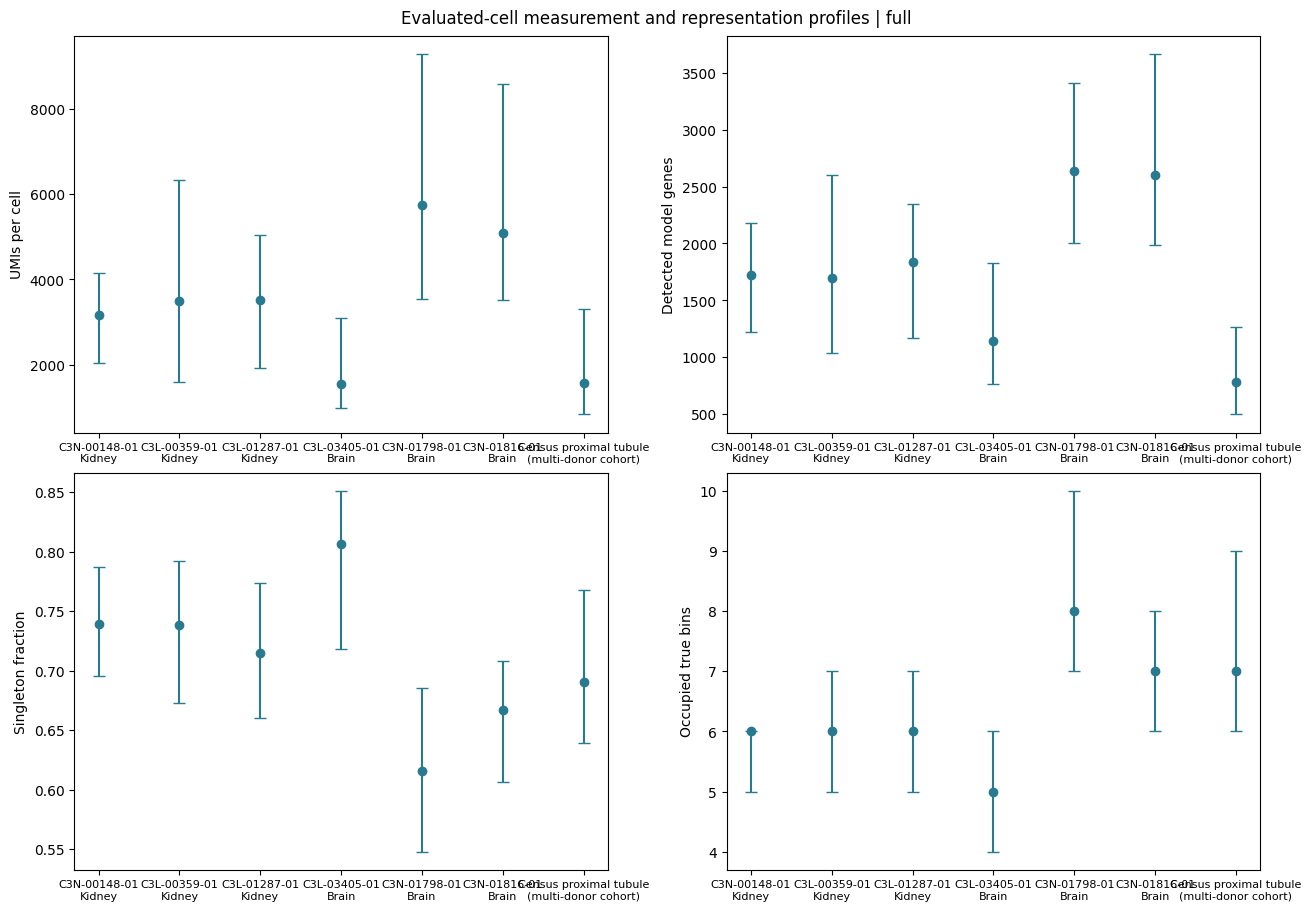

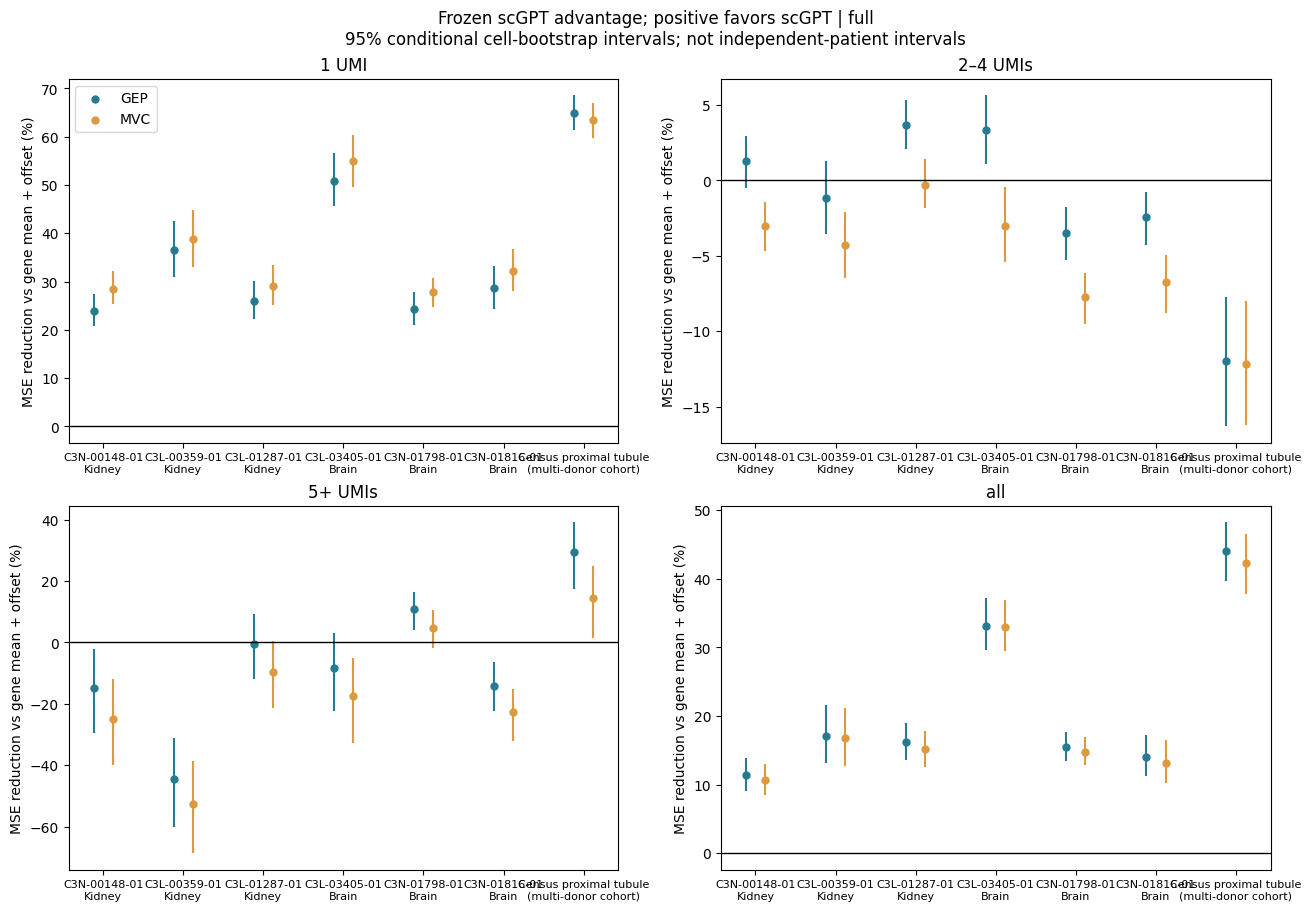

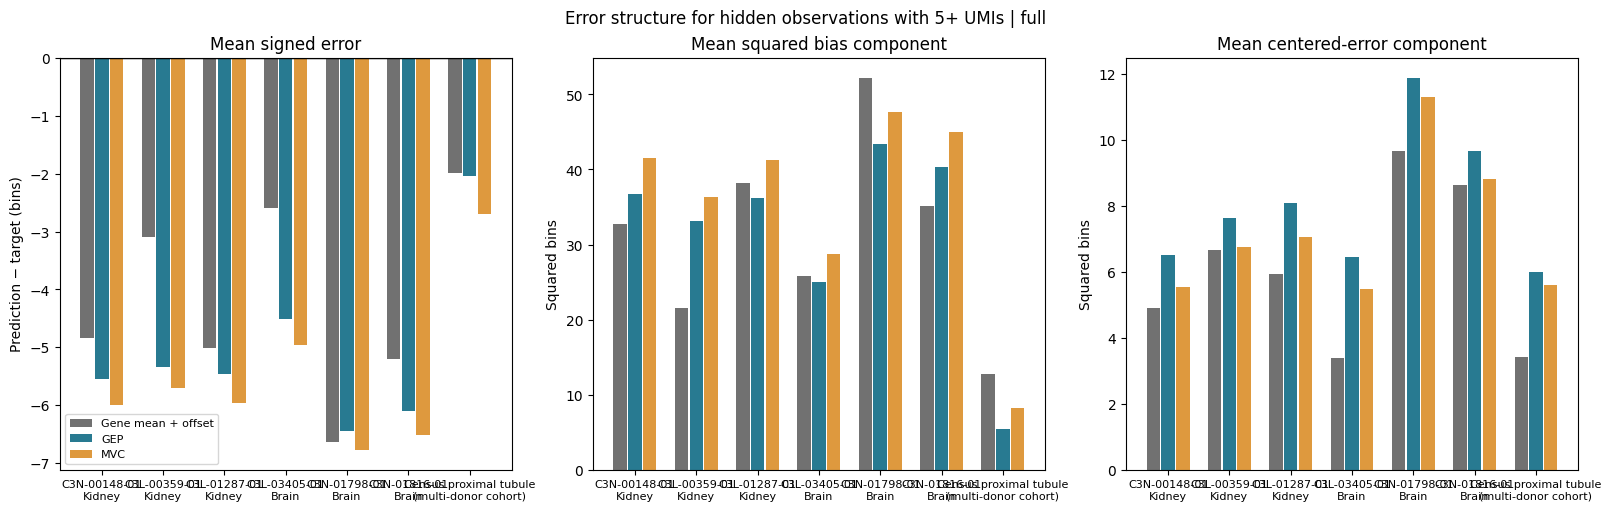

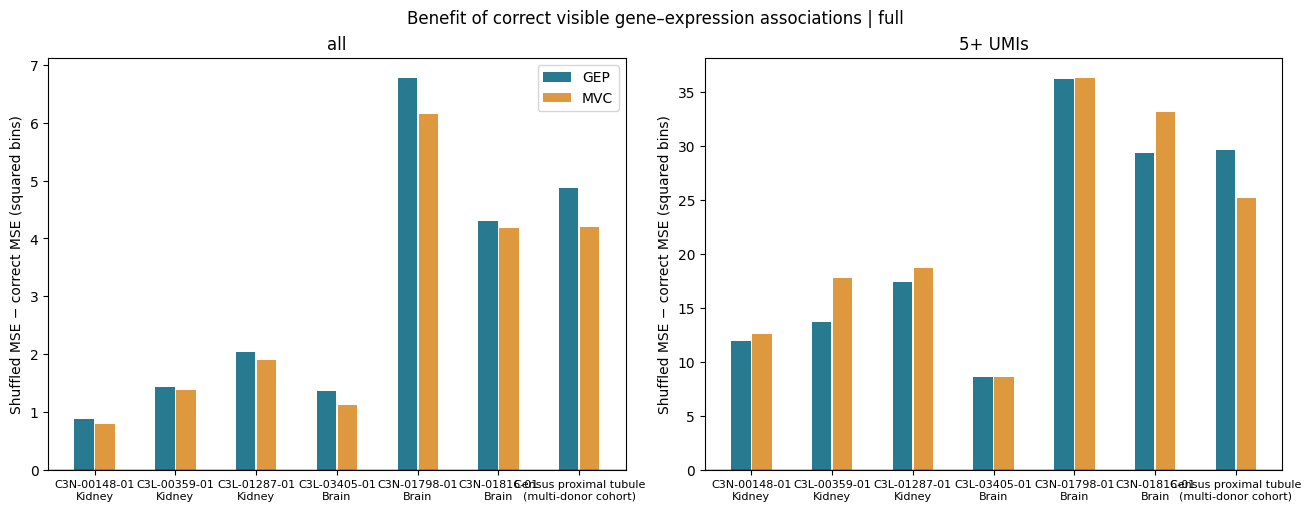

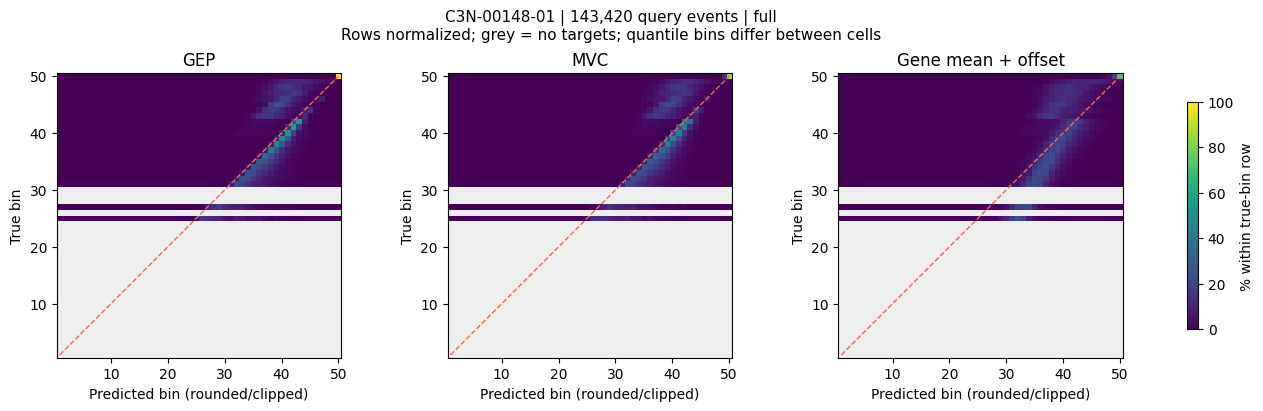

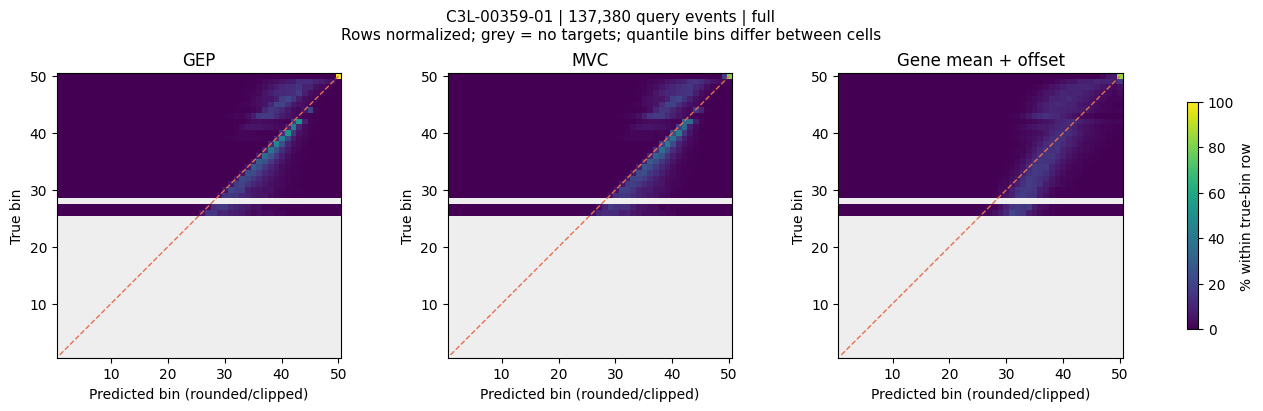

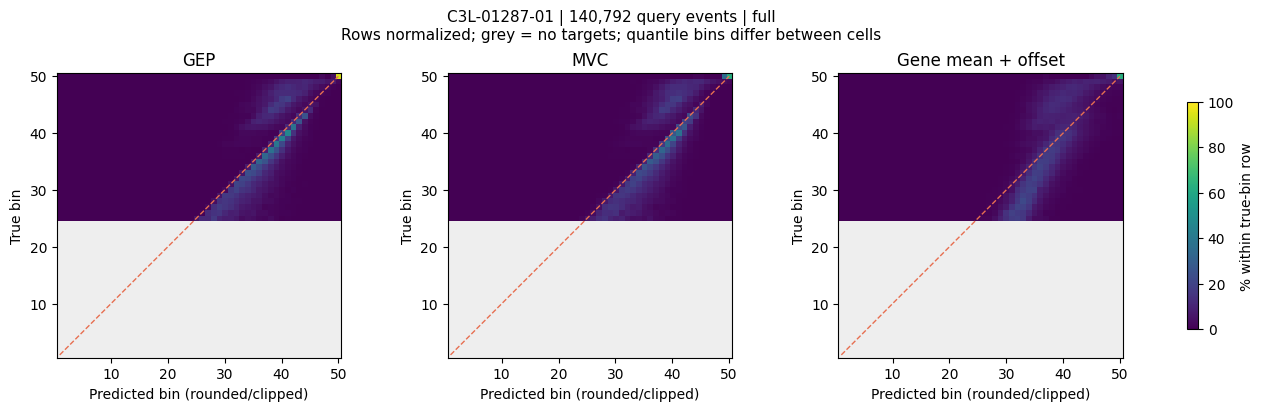

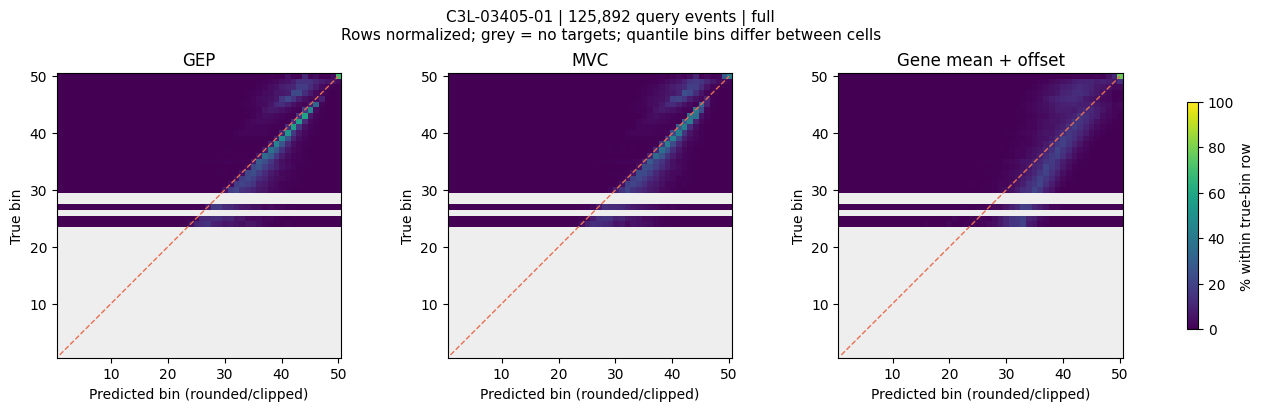

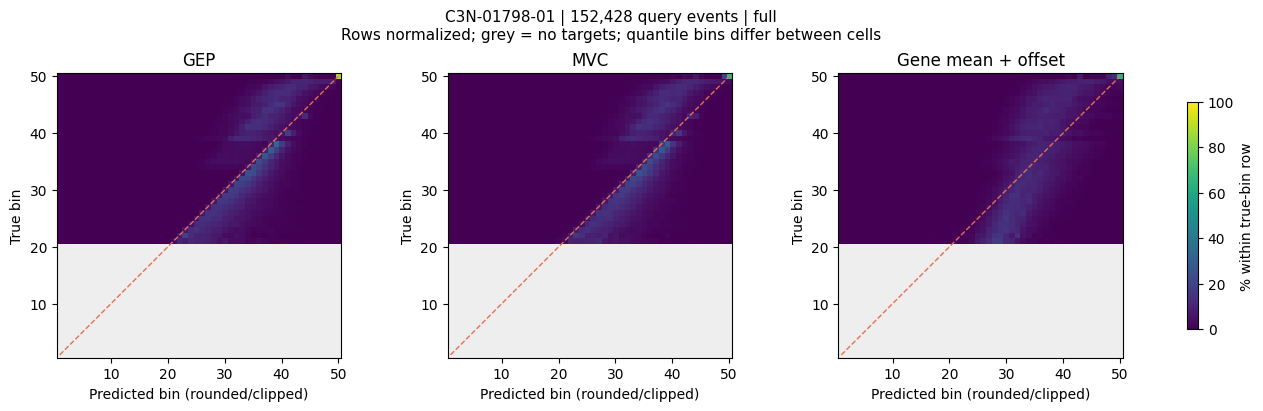

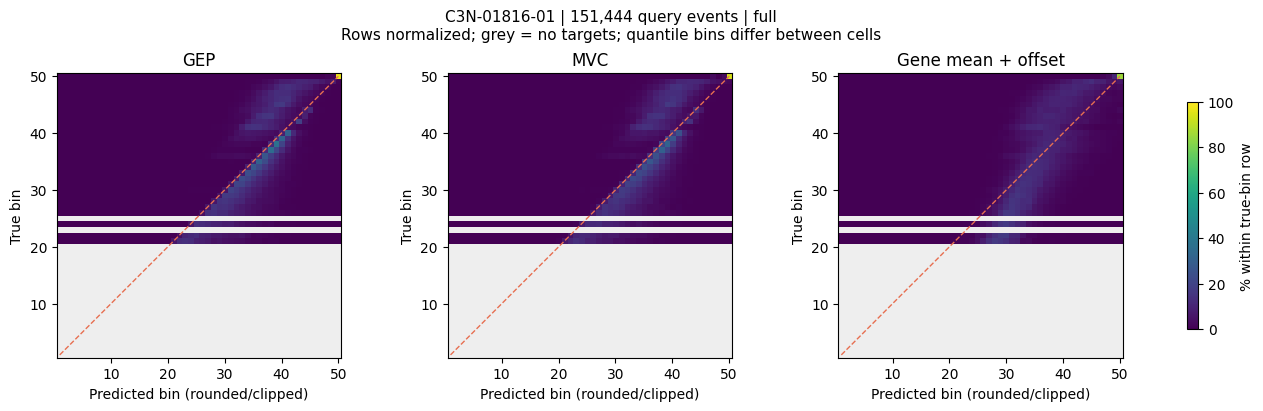

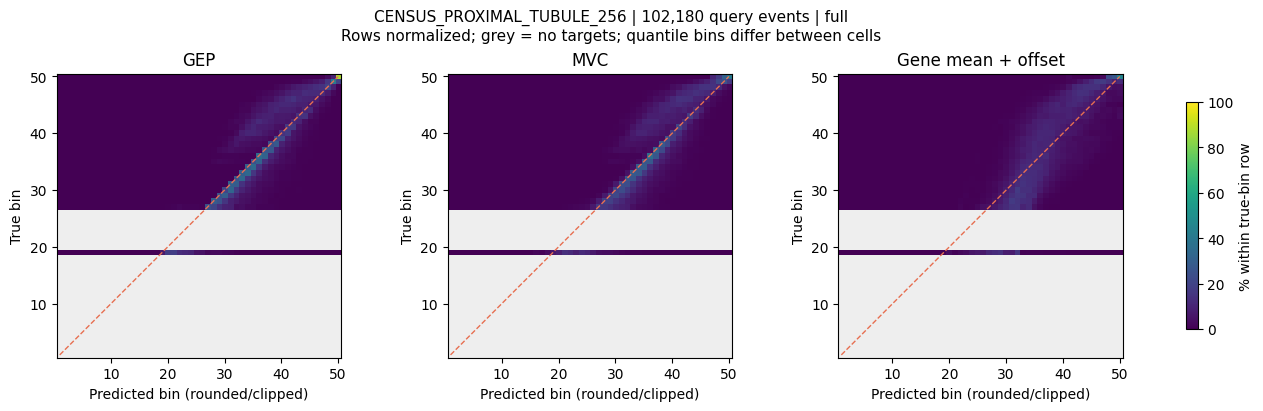

Figures: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full/figures


In [18]:
# 9 — Report figures. No inference; can also run directly after reload cell 10.
import matplotlib.pyplot as plt
from textwrap import fill
FIGURES=RUN_DIR/"figures"
FIGURES.mkdir(exist_ok=True)
order=unit_info.sample_id.tolist()
short={sid:("Census proximal tubule\n(multi-donor cohort)" if sid.startswith("CENSUS") else sid+"\n"+unit_info.set_index("sample_id").loc[sid,"tissue"]) for sid in order}
colors={"GEP":"#287A91","MVC":"#DE993E",BASELINE:"#717171"}
labels={"GEP":"GEP","MVC":"MVC",BASELINE:"Gene mean + offset"}

def save_report_figure(fig,name):
    fig.savefig(FIGURES/f"{name}.png",dpi=220,bbox_inches="tight")
    fig.savefig(FIGURES/f"{name}.pdf",bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Figure 1: evaluated-cell profiles, medians and IQRs (not confidence intervals).
metrics_to_plot=[("total_counts","UMIs per cell"),("model_detected_genes","Detected model genes"),
                 ("model_fraction_count_one","Singleton fraction"),("occupied_bins","Occupied true bins")]
fig,axes=plt.subplots(2,2,figsize=(13,9),constrained_layout=True)
for ax,(metric,label) in zip(axes.flat,metrics_to_plot):
    part=profiles.loc[(profiles.population=="evaluated")&(profiles.metric==metric)].set_index("sample_id").reindex(order)
    x=np.arange(len(order))
    ax.errorbar(x,part["median"],yerr=np.vstack([part["median"]-part.q25,part.q75-part["median"]]),fmt="o",capsize=4,color="#287A91")
    ax.set(xticks=x,xticklabels=[short[s] for s in order],ylabel=label)
    ax.tick_params(axis="x",labelsize=8)
fig.suptitle(f"Evaluated-cell measurement and representation profiles | {MODE}")
save_report_figure(fig,"01_data_profiles")

# Figure 2: paired advantage over the strong baseline, conditional cell intervals.
fig,axes=plt.subplots(2,2,figsize=(13,9),constrained_layout=True)
for ax,group in zip(axes.flat,COUNT_GROUPS):
    for head,offset in [("GEP",-.12),("MVC",.12)]:
        part=paired.loc[(paired.count_group==group)&(paired['head']==head)].set_index("sample_id").reindex(order)
        x=np.arange(len(order))+offset
        ax.vlines(x,part.percent_low,part.percent_high,color=colors[head],lw=1.5)
        ax.scatter(x,part.percent_MSE_reduction,color=colors[head],label=head,s=25)
    ax.axhline(0,color="black",lw=1)
    ax.set(title=group,ylabel="MSE reduction vs gene mean + offset (%)",xticks=np.arange(len(order)),xticklabels=[short[s] for s in order])
    ax.tick_params(axis="x",labelsize=8)
axes[0,0].legend()
fig.suptitle(f"Frozen scGPT advantage; positive favors scGPT | {MODE}\n95% conditional cell-bootstrap intervals; not independent-patient intervals",fontsize=12)
save_report_figure(fig,"02_paired_relative_performance")

# Figure 3: signed residuals and decomposition in the 5+ observed-UMI group.
fig,axes=plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
for j,method in enumerate([BASELINE,*HEADS]):
    part=decomposition.loc[(decomposition.count_group=="5+ UMIs")&(decomposition.method==method)].set_index("sample_id").reindex(order)
    x=np.arange(len(order))+(j-1)*.24
    axes[0].bar(x,part.mean_residual,width=.22,color=colors[method],label=labels[method])
    axes[1].bar(x,part.squared_bias,width=.22,color=colors[method])
    axes[2].bar(x,part.centered_MSE,width=.22,color=colors[method])
for ax,title,ylabel in zip(axes,["Mean signed error","Mean squared bias component","Mean centered-error component"],["Prediction − target (bins)","Squared bins","Squared bins"]):
    ax.set(title=title,ylabel=ylabel,xticks=np.arange(len(order)),xticklabels=[short[s] for s in order])
    ax.tick_params(axis="x",labelsize=8)
axes[0].axhline(0,color="black",lw=1)
axes[0].legend(fontsize=8)
fig.suptitle(f"Error structure for hidden observations with 5+ UMIs | {MODE}")
save_report_figure(fig,"03_higher_count_error_components")

# Figure 4: correct-vs-shuffled context, same queries. Not an estimate of biological signal fraction.
fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
for ax,group in zip(axes,["all","5+ UMIs"]):
    for head,offset in [("GEP",-.13),("MVC",.13)]:
        part=paired.loc[(paired.count_group==group)&(paired['head']==head)].set_index("sample_id").reindex(order)
        ax.bar(np.arange(len(order))+offset,part.context_gain,width=.24,color=colors[head],label=head)
    ax.axhline(0,color="black",lw=1)
    ax.set(title=group,ylabel="Shuffled MSE − correct MSE (squared bins)",xticks=np.arange(len(order)),xticklabels=[short[s] for s in order])
    ax.tick_params(axis="x",labelsize=8)
axes[0].legend()
fig.suptitle(f"Benefit of correct visible gene–expression associations | {MODE}")
save_report_figure(fig,"04_context_control")

# Appendix: row-normalized all-query regression-error maps, one unit at a time.
# Full numerical count matrices are saved too; each event is counted once per mask.
cmap=plt.get_cmap("viridis").copy();cmap.set_bad("#eeeeee")
for sid in order:
    q=pd.concat([pd.read_csv(RUN_DIR/sid/f"query_predictions_mask{s}.csv.gz",
          usecols=["target_bin",*HEADS,BASELINE]) for s in MASK_SEEDS],ignore_index=True)
    y=q.target_bin.to_numpy(dtype=int)
    fig,axes=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
    for ax,method in zip(axes,[*HEADS,BASELINE]):
        rounded=np.clip(np.floor(q[method].to_numpy()+.5),1,50).astype(int)
        cm=np.bincount((y-1)*50+rounded-1,minlength=2500).reshape(50,50)
        support=cm.sum(axis=1)
        pct=np.full((50,50),np.nan)
        np.divide(100*cm,support[:,None],out=pct,where=support[:,None]>0)
        image=ax.imshow(np.ma.masked_invalid(pct),origin="lower",extent=[.5,50.5,.5,50.5],vmin=0,vmax=100,cmap=cmap,interpolation="nearest")
        ax.plot([1,50],[1,50],"--",color="#e76f51",lw=1)
        ax.set(title=labels[method],xlabel="Predicted bin (rounded/clipped)",ylabel="True bin")
        pd.DataFrame(cm,index=np.arange(1,51),columns=np.arange(1,51)).to_csv(FIGURES/f"heatmap_counts_{sid}_{method}.csv",index_label="true_bin")
    fig.colorbar(image,ax=axes,label="% within true-bin row",shrink=.8)
    fig.suptitle(f"{sid} | {len(q):,} query events | {MODE}\nRows normalized; grey = no targets; quantile bins differ between cells",fontsize=11)
    save_report_figure(fig,f"appendix_heatmaps_{sid}")
print("Figures:",FIGURES)


In [19]:
# 10 — Standalone reload. Run this cell alone, then cell 9; no model or raw data needed.
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display
ROOT=Path.home()/"scgpt-cna"
MODE_TO_LOAD="full"  # Use "pilot" for the initial check.
RUN_TO_LOAD=None      # Or an explicit timestamped directory.
RESULTS_ROOT=ROOT/"report_benchmark/results"
RUN_DIR=Path(RUN_TO_LOAD) if RUN_TO_LOAD is not None else Path(json.loads((RESULTS_ROOT/f"latest_{MODE_TO_LOAD}_run.json").read_text())["run_dir"])
m=json.loads((RUN_DIR/"run_manifest.json").read_text())
MODE=m["mode"];MASK_SEEDS=m["mask_seeds"]
BASELINE="gene_mean_plus_offset";HEADS=["GEP","MVC"]
COUNT_GROUPS=["1 UMI","2–4 UMIs","5+ UMIs","all"]
all_summary=pd.read_csv(RUN_DIR/"all_specimens_summary.csv")
all_per_cell=pd.read_csv(RUN_DIR/"all_specimens_cell_scores.csv")
profiles=pd.read_csv(RUN_DIR/"measurement_profiles.csv")
paired=pd.read_csv(RUN_DIR/"paired_comparisons.csv")
decomposition=pd.read_csv(RUN_DIR/"error_decomposition.csv")
unit_info=pd.read_csv(RUN_DIR/"evaluation_unit_metadata.csv")
query_coverage=pd.read_csv(RUN_DIR/"query_coverage.csv")
coverage_summary=pd.read_csv(RUN_DIR/"coverage_summary.csv")
print("Loaded saved evidence:",RUN_DIR)
display(all_summary.query("count_group == 'all'").round(3))
print("Cell 9 can regenerate every figure; no inference is performed.")


Loaded saved evidence: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full


/tmp/ipykernel_2031616/2986700178.py:17: DtypeWarning: Columns (50,51,52,53,54,55,56,59) have mixed types. Specify dtype option on import or set low_memory=False.
  all_per_cell=pd.read_csv(RUN_DIR/"all_specimens_cell_scores.csv")


,sample_id,case_id,count_group,method,n_cells,mean_MSE,median_MSE,mean_MAE,mean_MSE_gain,cells_beating_baseline,mean_baseline_MSE,percent_MSE_reduction,tissue,diagnosis,source,evaluation_unit
24,C3N-00148-01,C3N-00148,all,GEP,128,14.450,14.094,2.908,1.869,95,16.318,11.450,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
25,C3N-00148-01,C3N-00148,all,GEP_shuffled,128,15.330,14.896,3.282,0.989,81,16.318,6.059,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
26,C3N-00148-01,C3N-00148,all,MVC,128,14.577,14.297,2.872,1.742,94,16.318,10.673,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
27,C3N-00148-01,C3N-00148,all,MVC_shuffled,128,15.362,14.967,3.207,0.956,81,16.318,5.860,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
28,C3N-00148-01,C3N-00148,all,gene_mean,128,21.272,18.399,3.780,-4.954,8,16.318,-30.356,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
29,C3N-00148-01,C3N-00148,all,gene_mean_plus_offset,128,16.318,15.300,3.187,0.000,0,16.318,0.000,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
30,C3N-00148-01,C3N-00148,all,reference_constant,128,23.349,19.484,4.004,-7.030,1,16.318,-43.081,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
31,C3N-00148-01,C3N-00148,all,visible_mean,128,17.931,17.163,3.479,-1.612,32,16.318,-9.880,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
56,C3L-00359-01,C3L-00359,all,GEP,128,15.007,13.520,2.917,3.101,94,18.108,17.127,Kidney,"Renal cell carcinoma, NOS",Lab,specimen
57,C3L-00359-01,C3L-00359,all,GEP_shuffled,128,16.437,14.862,3.401,1.672,76,18.108,9.231,Kidney,"Renal cell carcinoma, NOS",Lab,specimen


Cell 9 can regenerate every figure; no inference is performed.


### 2. Explaining errors 

Do the cells where scGPT loses have anything in common?

In [1]:
# 1 — Reload the completed benchmark and construct one paired row per cell/head/group.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.home() / "scgpt-cna"
MODE_TO_LOAD = "full"  # Use "pilot" only for a preliminary check.
RUN_TO_LOAD = None     # Or Path("/absolute/path/to/report_benchmark/results/timestamp_full")
if RUN_TO_LOAD is None:
    pointer = ROOT / "report_benchmark/results" / f"latest_{MODE_TO_LOAD}_run.json"
    assert pointer.is_file(), "No completed benchmark pointer. Set RUN_TO_LOAD or complete benchmark cell 8."
    P1_RUN = Path(json.loads(pointer.read_text())["run_dir"])
else:
    P1_RUN = Path(RUN_TO_LOAD)
P1_MANIFEST = json.loads((P1_RUN/"run_manifest.json").read_text())
P1_MODE = P1_MANIFEST["mode"]
if P1_MODE != "full":
    print("PILOT DATA: descriptive execution check, not final report evidence.")
P1_META = pd.read_csv(P1_RUN/"evaluation_unit_metadata.csv")
P1_SCORES = pd.read_csv(P1_RUN/"all_specimens_cell_scores.csv")
P1_MASKS = list(map(int,P1_MANIFEST["mask_seeds"]))
P1_GROUPS = ["all", "1 UMI", "2–4 UMIs", "5+ UMIs"]
P1_HEADS = ["GEP", "MVC"]
P1_BASELINE = "gene_mean_plus_offset"
P1_KEYS = ["sample_id", "cell_id", "count_group"]
assert not P1_SCORES.duplicated(P1_KEYS+["method"]).any()
assert P1_META.sample_id.is_unique
required = [*P1_KEYS,"method","MSE","MAE","n_masks","model_detected_genes",
    "total_counts","model_fraction_count_one","visible_gene_fraction","target_std",
    "gene_baseline_support_fraction"]
assert set(required).issubset(P1_SCORES), "Use the new report benchmark exports, not the older multicase summaries."
baseline = P1_SCORES.loc[P1_SCORES.method.eq(P1_BASELINE),
    P1_KEYS+["MSE","MAE","n_masks"]].rename(columns={"MSE":"baseline_MSE","MAE":"baseline_MAE","n_masks":"baseline_n_masks"})
P1 = P1_SCORES.loc[P1_SCORES.method.isin(P1_HEADS)].copy()
# baseline_MSE already exists in the original score file: validate and replace explicitly.
P1 = P1.rename(columns={"baseline_MSE":"previous_baseline_MSE"})
P1 = P1.merge(baseline,on=P1_KEYS,validate="many_to_one",how="left")
assert P1.baseline_MSE.notna().all()
assert P1.n_masks.eq(P1.baseline_n_masks).all()
if "previous_baseline_MSE" in P1:
    np.testing.assert_allclose(P1.previous_baseline_MSE,P1.baseline_MSE)
P1["gain"] = P1.baseline_MSE-P1.MSE
if "MSE_gain" in P1:
    np.testing.assert_allclose(P1.gain,P1.MSE_gain,atol=1e-7)
assert np.isfinite(P1[["MSE","baseline_MSE","gain"]].to_numpy()).all()
assert P1.loc[P1.count_group.eq("all"),"n_masks"].eq(len(P1_MASKS)).all()
# Do not merge labels from mutable notebook globals or assume all cells in a tumor are malignant.
P1 = P1.drop(columns=[c for c in ["tissue","diagnosis","source","evaluation_unit"] if c in P1])
P1 = P1.merge(P1_META[["sample_id","tissue","diagnosis","source","evaluation_unit"]],on="sample_id",validate="many_to_one")
P1_ORDER = P1_META.sample_id.tolist()
P1_OUT = P1_RUN / "priority1" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
P1_OUT.mkdir(parents=True,exist_ok=False)
P1.to_csv(P1_OUT/"paired_cell_diagnostics.csv",index=False)
(P1_OUT/"source_manifest.json").write_text(json.dumps({"benchmark_run":str(P1_RUN),"mode":P1_MODE,
    "benchmark_manifest_sha256":hashlib.sha256((P1_RUN/"run_manifest.json").read_bytes()).hexdigest(),
    "scores_sha256":hashlib.sha256((P1_RUN/"all_specimens_cell_scores.csv").read_bytes()).hexdigest(),
    "weighting":"Each row is one cell/head/group, masks averaged first; no cross-specimen pooling"},indent=2))
print("Loaded:",P1_RUN)
print("Saving diagnostics:",P1_OUT)
display(P1.groupby(["sample_id","count_group","method"],as_index=False).agg(
    n_cells=("cell_id","nunique"),mean_model_MSE=("MSE","mean"),mean_baseline_MSE=("baseline_MSE","mean"),mean_gain=("gain","mean")).round(3))


/tmp/ipykernel_881490/2972682596.py:24: DtypeWarning: Columns (50,51,52,53,54,55,56,59) have mixed types. Specify dtype option on import or set low_memory=False.
  P1_SCORES = pd.read_csv(P1_RUN/"all_specimens_cell_scores.csv")


Loaded: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full
Saving diagnostics: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full/priority1/20261116T190952283403Z


,sample_id,count_group,method,n_cells,mean_model_MSE,mean_baseline_MSE,mean_gain
0,C3L-00359-01,1 UMI,GEP,128,8.307,13.084,4.777
1,C3L-00359-01,1 UMI,MVC,128,8.003,13.084,5.081
2,C3L-00359-01,2–4 UMIs,GEP,128,30.540,30.192,-0.348
3,C3L-00359-01,2–4 UMIs,MVC,128,31.489,30.192,-1.297
4,C3L-00359-01,5+ UMIs,GEP,128,40.734,28.189,-12.545
5,C3L-00359-01,5+ UMIs,MVC,128,43.080,28.189,-14.891
6,C3L-00359-01,all,GEP,128,15.007,18.108,3.101
7,C3L-00359-01,all,MVC,128,15.077,18.108,3.031
8,C3L-01287-01,1 UMI,GEP,128,10.018,13.536,3.518
9,C3L-01287-01,1 UMI,MVC,128,9.594,13.536,3.942


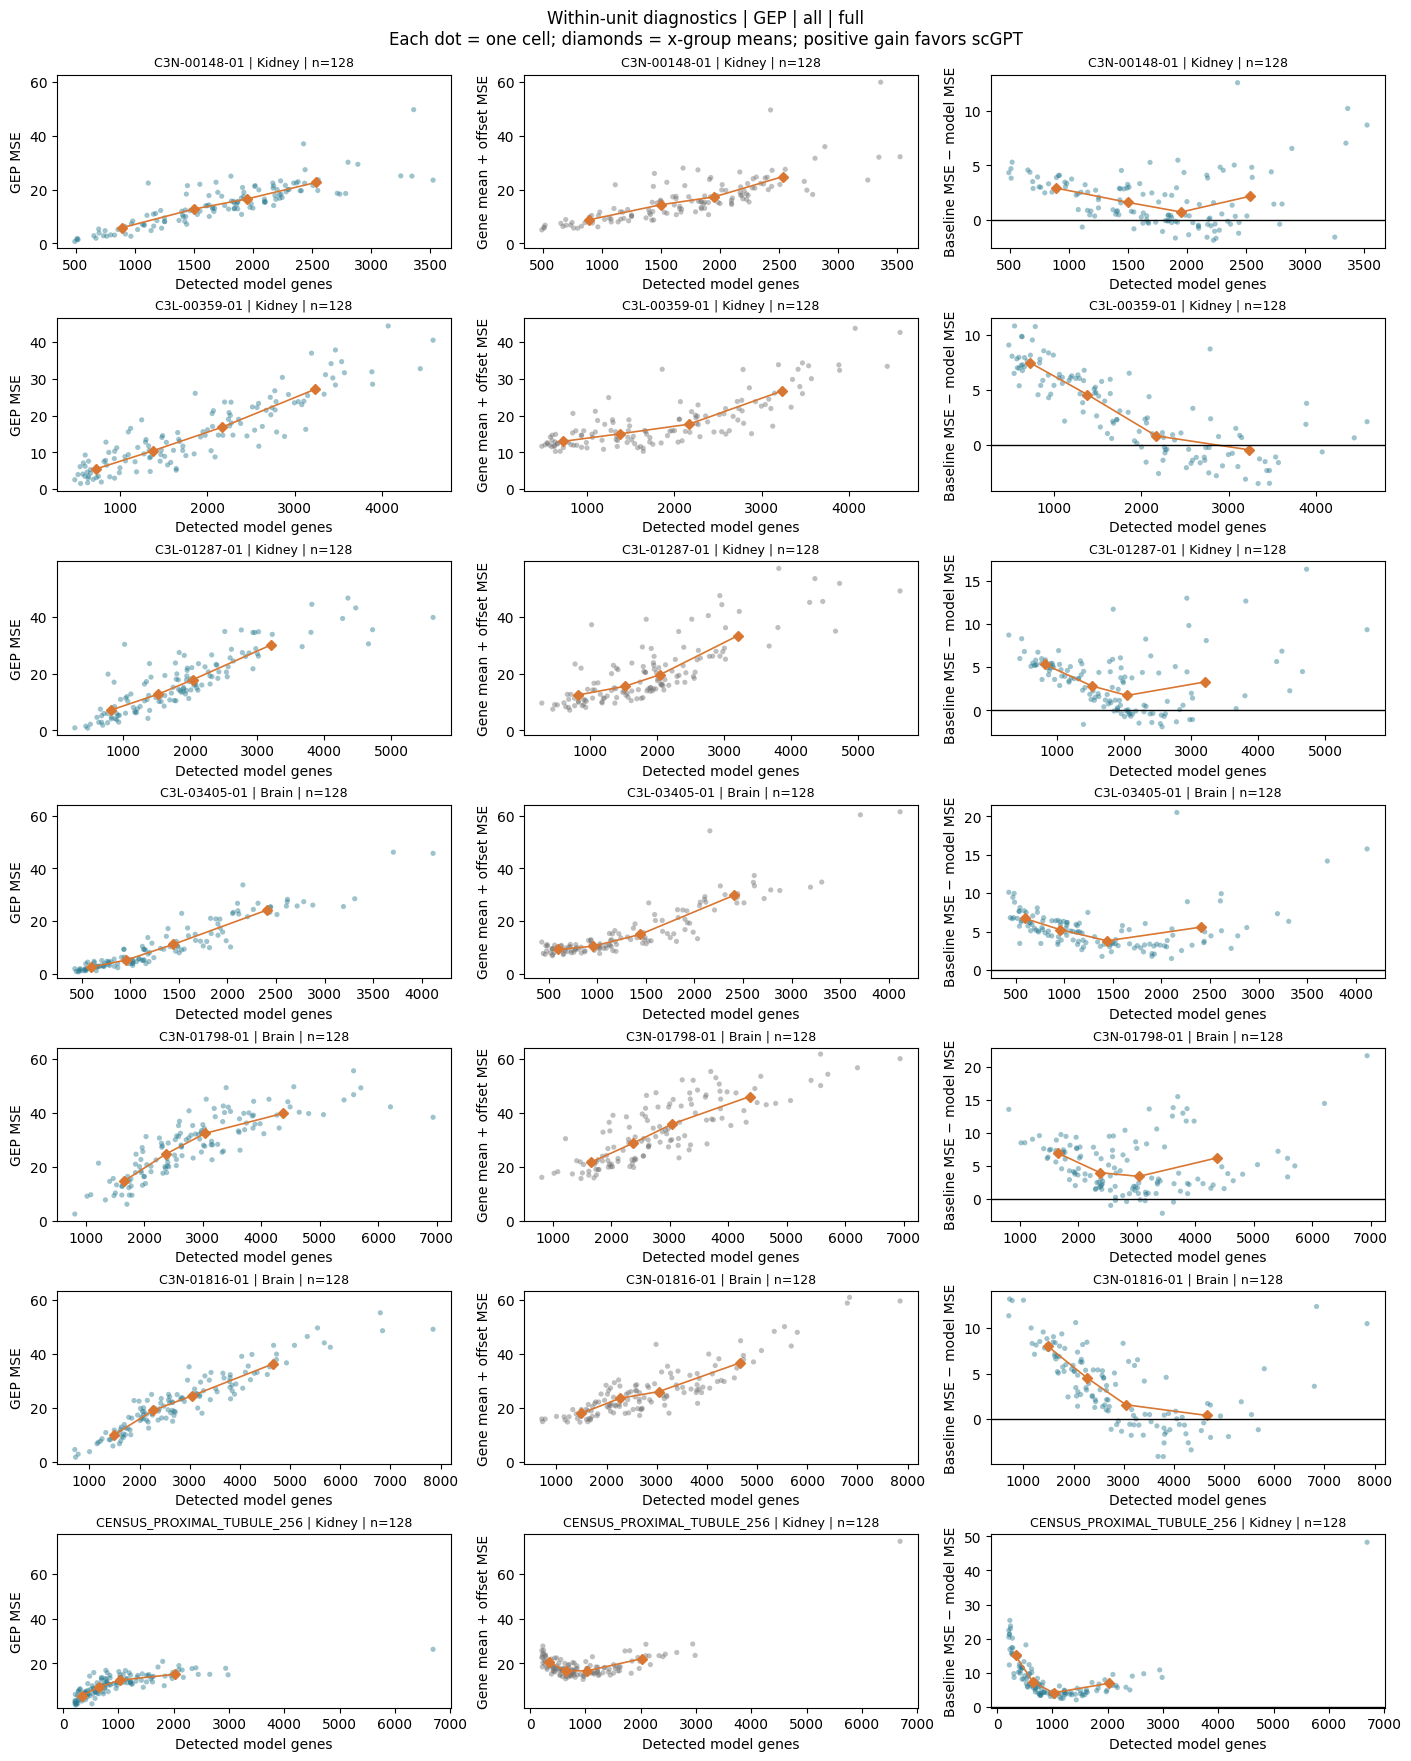

Read all three columns together: does model error change, baseline error change, or both?
These are observational comparisons across cells; they do not isolate a context effect.


In [2]:
# 2 — Adjustable diagnostic figure. Rerun this cell for another head/group/property.
P1_HEAD = "GEP"
P1_GROUP = "all"  # "1 UMI", "2–4 UMIs", "5+ UMIs"
P1_FEATURE = "model_detected_genes"
# Other choices: visible_gene_fraction, model_fraction_count_one, total_counts,
#               target_std, gene_baseline_support_fraction
P1_SAMPLES = None  # None = all; or ["C3N-00148-01", "CENSUS_PROXIMAL_TUBULE_256"]

P1_FEATURE_LABELS = {
 "model_detected_genes":"Detected model genes",
 "visible_gene_fraction":"Fraction of detected model genes visible",
 "model_fraction_count_one":"Fraction of detected model genes with 1 UMI",
 "total_counts":"Observed total UMIs",
 "target_std":"Mean within-mask target SD (bins)",
 "gene_baseline_support_fraction":"Mean fraction of queries detected in reference cells",
}
assert P1_HEAD in P1_HEADS and P1_GROUP in P1_GROUPS and P1_FEATURE in P1_FEATURE_LABELS
chosen = P1_ORDER if P1_SAMPLES is None else P1_SAMPLES
assert set(chosen).issubset(P1_ORDER)
fig,axes = plt.subplots(len(chosen),3,figsize=(14,max(3,2.5*len(chosen))),squeeze=False,constrained_layout=True)
p1_trends=[]
for row,sid in enumerate(chosen):
    part=P1.loc[P1.sample_id.eq(sid)&P1.method.eq(P1_HEAD)&P1.count_group.eq(P1_GROUP)].copy()
    part=part.loc[np.isfinite(pd.to_numeric(part[P1_FEATURE],errors="coerce"))]
    meta=P1_META.set_index("sample_id").loc[sid]
    for col,(outcome,label,color) in enumerate([
        ("MSE",f"{P1_HEAD} MSE","#287A91"),
        ("baseline_MSE","Gene mean + offset MSE","#717171"),
        ("gain","Baseline MSE − model MSE","#287A91")]):
        ax=axes[row,col]
        ax.scatter(part[P1_FEATURE],part[outcome],s=14,alpha=.45,color=color,edgecolors="none")
        if len(part)>=8 and part[P1_FEATURE].nunique()>=4:
            buckets=pd.qcut(part[P1_FEATURE],q=4,duplicates="drop")
            trend=part.groupby(buckets,observed=True).agg(x=(P1_FEATURE,"mean"),y=(outcome,"mean"),n_cells=("cell_id","size"))
            ax.plot(trend.x,trend.y,"D-",color="#D97732",ms=5,lw=1.2)
            p1_trends.append(trend.reset_index(drop=True).assign(sample_id=sid,outcome=outcome,feature=P1_FEATURE,head=P1_HEAD,count_group=P1_GROUP))
        if outcome=="gain":ax.axhline(0,color="black",lw=1)
        ax.set(xlabel=P1_FEATURE_LABELS[P1_FEATURE],ylabel=label)
        ax.set_title(f"{sid} | {meta['tissue']} | n={len(part)}",fontsize=9)
        if not len(part):ax.text(.5,.5,"No contributing cells",ha="center",transform=ax.transAxes)
for row_axes in axes:
    limits=[ax.get_ylim() for ax in row_axes[:2]]
    common=(min(p[0] for p in limits),max(p[1] for p in limits))
    for ax in row_axes[:2]:ax.set_ylim(common)
fig.suptitle(f"Within-unit diagnostics | {P1_HEAD} | {P1_GROUP} | {P1_MODE}\nEach dot = one cell; diamonds = x-group means; positive gain favors scGPT",fontsize=12)
slug={"all":"all","1 UMI":"1UMI","2–4 UMIs":"2to4","5+ UMIs":"5plus"}[P1_GROUP]
tag=f"{P1_HEAD}_{slug}_{P1_FEATURE}"
fig.savefig(P1_OUT/f"diagnostic_{tag}.png",dpi=200,bbox_inches="tight")
fig.savefig(P1_OUT/f"diagnostic_{tag}.pdf",bbox_inches="tight")
plt.show();plt.close(fig)
if p1_trends:pd.concat(p1_trends,ignore_index=True).to_csv(P1_OUT/f"descriptive_trends_{tag}.csv",index=False)
print("Read all three columns together: does model error change, baseline error change, or both?")
print("These are observational comparisons across cells; they do not isolate a context effect.")


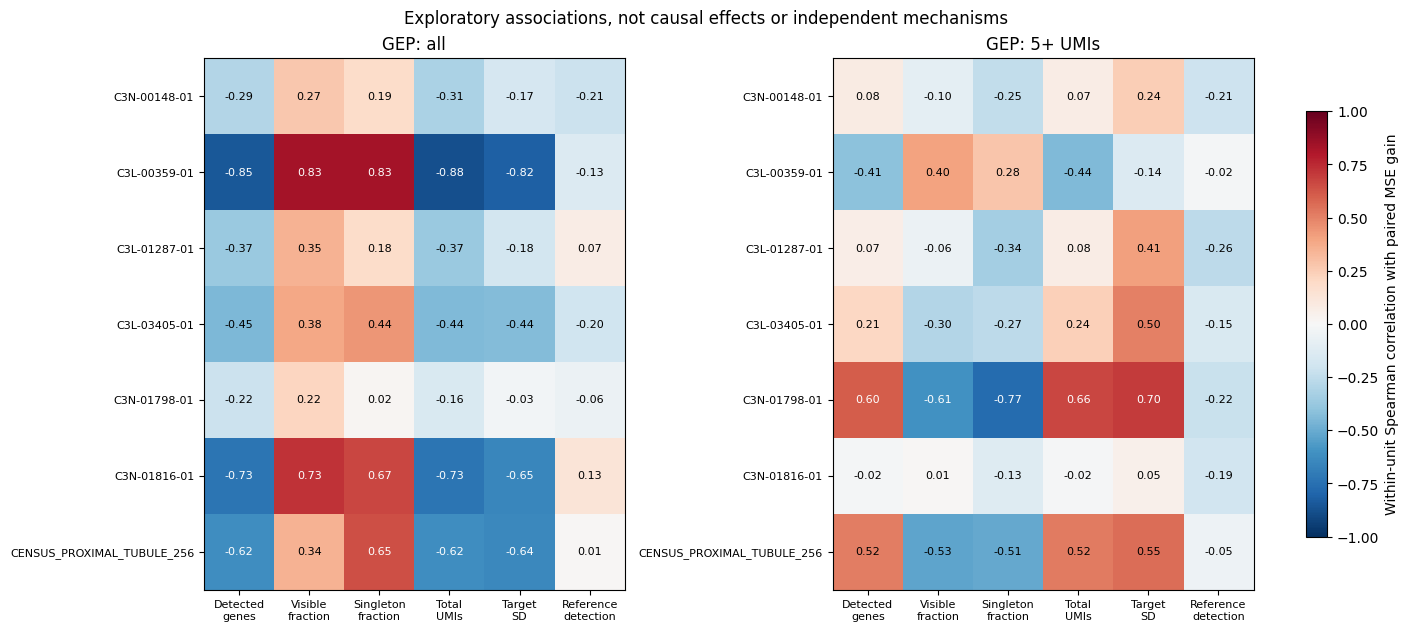

,sample_id,head,count_group,feature,outcome,n_cells,n_unique_x,spearman_rho,status
56,C3L-00359-01,GEP,all,model_detected_genes,gain,128,126,-0.847,descriptive
59,C3L-00359-01,GEP,all,visible_gene_fraction,gain,128,117,0.834,descriptive
62,C3L-00359-01,GEP,all,model_fraction_count_one,gain,128,127,0.833,descriptive
65,C3L-00359-01,GEP,all,total_counts,gain,128,127,-0.877,descriptive
68,C3L-00359-01,GEP,all,target_std,gain,128,128,-0.819,descriptive
71,C3L-00359-01,GEP,all,gene_baseline_support_fraction,gain,128,60,-0.134,descriptive
200,C3L-01287-01,GEP,all,model_detected_genes,gain,128,125,-0.374,descriptive
203,C3L-01287-01,GEP,all,visible_gene_fraction,gain,128,114,0.349,descriptive
206,C3L-01287-01,GEP,all,model_fraction_count_one,gain,128,128,0.183,descriptive
209,C3L-01287-01,GEP,all,total_counts,gain,128,127,-0.370,descriptive


Detected genes and visible fraction largely describe the same fixed-budget constraint.
Target SD vs MSE can be mechanical. Grey = constant/insufficient, not zero association.


In [3]:
# 3 — Compact associations across all properties/groups; one correlation per unit, never pooled.
p1_associations=[]
for (sid,head,group),part in P1.groupby(["sample_id","method","count_group"]):
    for feature in P1_FEATURE_LABELS:
        for outcome in ["MSE","baseline_MSE","gain"]:
            finite=part[[feature,outcome]].replace([np.inf,-np.inf],np.nan).dropna()
            valid=len(finite)>=8 and finite[feature].nunique()>1 and finite[outcome].nunique()>1
            rho=finite[feature].rank().corr(finite[outcome].rank()) if valid else np.nan
            p1_associations.append({"sample_id":sid,"head":head,"count_group":group,"feature":feature,
                "outcome":outcome,"n_cells":len(finite),"n_unique_x":finite[feature].nunique(),
                "spearman_rho":rho,"status":"descriptive" if valid else "constant_or_insufficient"})
P1_ASSOCIATIONS=pd.DataFrame(p1_associations)
P1_ASSOCIATIONS.to_csv(P1_OUT/"within_unit_spearman.csv",index=False)
features=list(P1_FEATURE_LABELS)
fig,axes=plt.subplots(1,2,figsize=(14,max(4,len(P1_ORDER)*.6+2)),constrained_layout=True)
cmap=plt.get_cmap("RdBu_r").copy();cmap.set_bad("#eeeeee")
for ax,group in zip(axes,["all","5+ UMIs"]):
    part=P1_ASSOCIATIONS.loc[P1_ASSOCIATIONS['head'].eq(P1_HEAD)&P1_ASSOCIATIONS.count_group.eq(group)&P1_ASSOCIATIONS.outcome.eq("gain")]
    table=part.pivot(index="sample_id",columns="feature",values="spearman_rho").reindex(index=P1_ORDER,columns=features)
    im=ax.imshow(np.ma.masked_invalid(table.to_numpy()),vmin=-1,vmax=1,cmap=cmap,aspect="auto")
    ax.set(xticks=range(len(features)),xticklabels=["Detected\ngenes","Visible\nfraction","Singleton\nfraction","Total\nUMIs","Target\nSD","Reference\ndetection"],
           yticks=range(len(P1_ORDER)),yticklabels=P1_ORDER,title=f"{P1_HEAD}: {group}")
    ax.tick_params(labelsize=8)
    for i in range(len(table)):
        for j in range(len(features)):
            value=table.iloc[i,j]
            if np.isfinite(value):ax.text(j,i,f"{value:.2f}",ha="center",va="center",fontsize=8,color="white" if abs(value)>.6 else "black")
fig.colorbar(im,ax=axes,label="Within-unit Spearman correlation with paired MSE gain",shrink=.8)
fig.suptitle("Exploratory associations, not causal effects or independent mechanisms",fontsize=12)
fig.savefig(P1_OUT/f"gain_associations_{P1_HEAD}.png",dpi=220,bbox_inches="tight")
fig.savefig(P1_OUT/f"gain_associations_{P1_HEAD}.pdf",bbox_inches="tight")
plt.show();plt.close(fig)
display(P1_ASSOCIATIONS.loc[P1_ASSOCIATIONS['head'].eq(P1_HEAD)&P1_ASSOCIATIONS.count_group.eq("all")&P1_ASSOCIATIONS.outcome.eq("gain")].round(3))
print("Detected genes and visible fraction largely describe the same fixed-budget constraint.")
print("Target SD vs MSE can be mechanical. Grey = constant/insufficient, not zero association.")


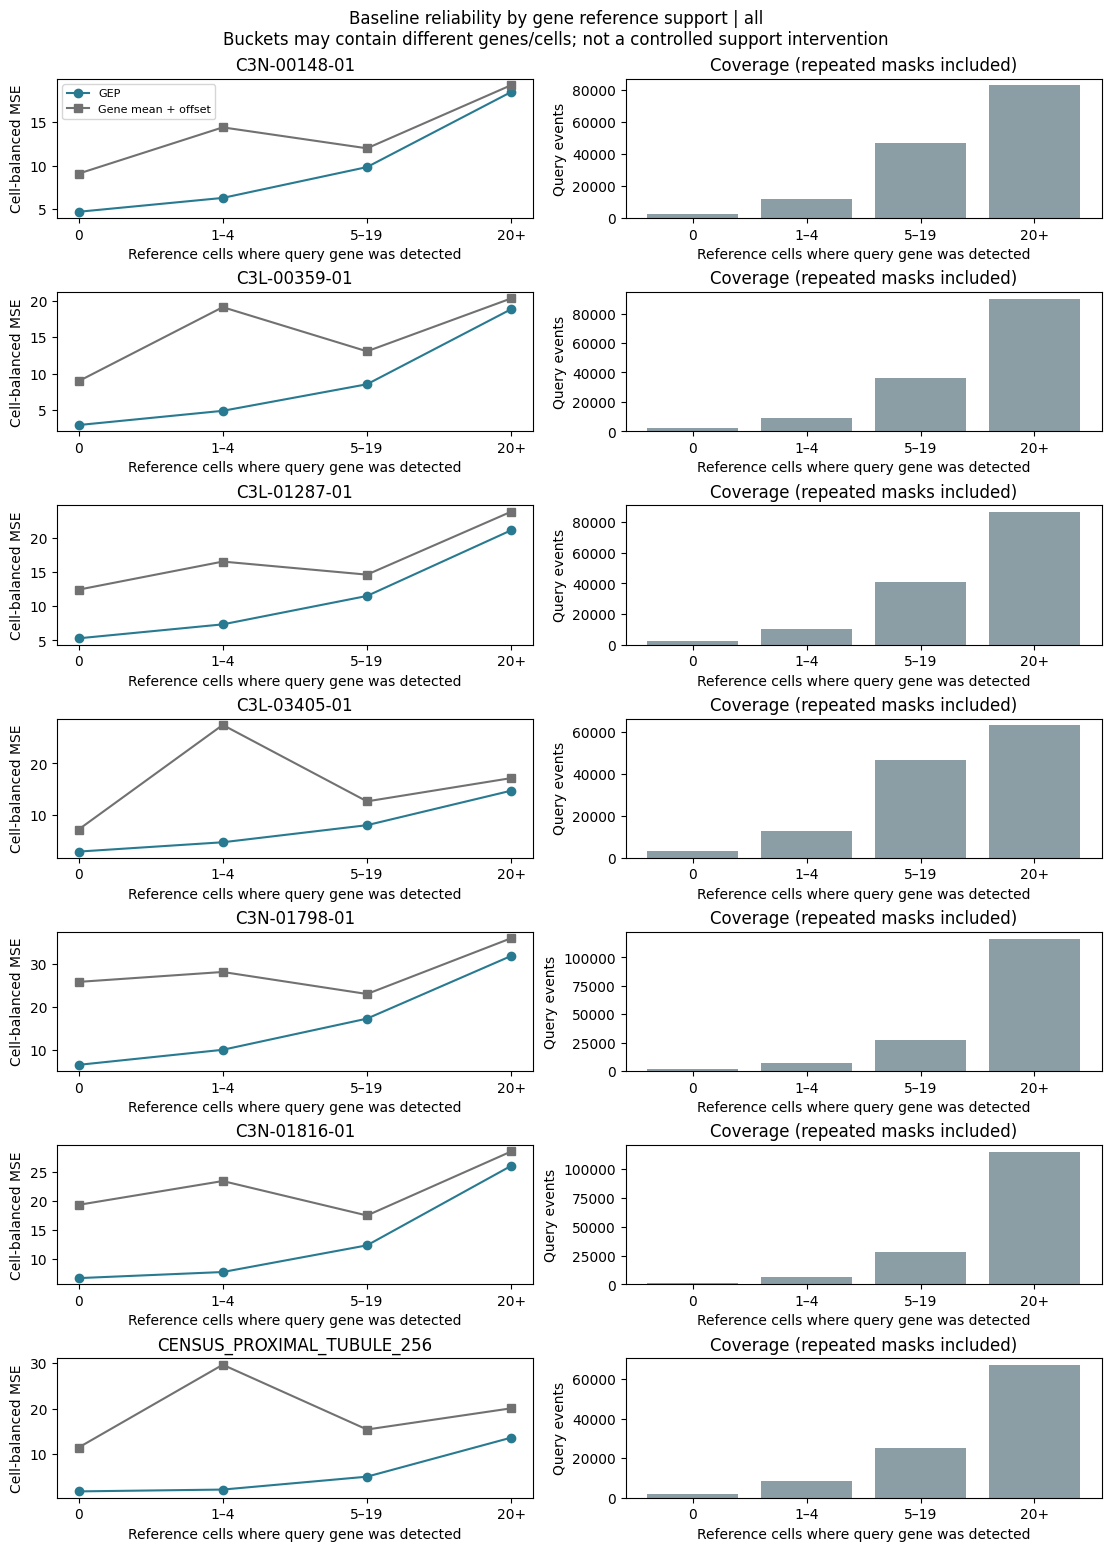

,sample_id,head,count_group,support_bucket,n_cells,n_query_events,unique_cell_gene_pairs,mean_masks_per_contributing_cell,cell_balanced_model_MSE,cell_balanced_baseline_MSE,cell_balanced_gain
0,C3N-00148-01,GEP,all,0,128,2659,2052,3.945,4.698,9.082,4.383
1,C3N-00148-01,GEP,all,1–4,128,11603,8946,4.000,6.293,14.404,8.111
2,C3N-00148-01,GEP,all,5–19,128,46554,35790,4.000,9.837,11.996,2.159
3,C3N-00148-01,GEP,all,20+,128,82604,63149,4.000,18.472,19.258,0.786
4,C3L-00359-01,GEP,all,0,128,2041,1593,3.914,2.961,8.965,6.005
5,C3L-00359-01,GEP,all,1–4,128,8893,6905,4.000,4.910,19.106,14.196
6,C3L-00359-01,GEP,all,5–19,128,36331,28444,4.000,8.547,13.059,4.511
7,C3L-00359-01,GEP,all,20+,128,90115,70174,4.000,18.830,20.304,1.475
8,C3L-01287-01,GEP,all,0,128,2570,2031,3.898,5.294,12.396,7.102
9,C3L-01287-01,GEP,all,1–4,128,10268,8034,4.000,7.331,16.497,9.166


0 = no detected reference observations; the gene mean falls back to the reference constant.
If a bucket is sparse, do not interpret its mean as a stable performance estimate.
All outputs: /home/akash1/scgpt-cna/report_benchmark/results/20261114T213609648407Z_full/priority1/20261116T190952283403Z


In [4]:
# 4 — Does the gene baseline fail where a gene has little reference support?
# Uses saved query files; no raw-count loading or new predictions.
P1_SUPPORT_GROUP = "all"  # Rerun for "5+ UMIs" to examine that subgroup.
assert P1_SUPPORT_GROUP in P1_GROUPS
support_labels=["0","1–4","5–19","20+"]
p1_support_rows=[]
p1_support_provenance=[]
for sid in P1_ORDER:
    files=[P1_RUN/sid/f"query_predictions_mask{s}.csv.gz" for s in P1_MASKS]
    use=["cell_id","mask_seed","gene_token","original_umi","reference_support","target_bin",P1_HEAD,P1_BASELINE]
    frames=[]
    for seed,path in zip(P1_MASKS,files):
        frame=pd.read_csv(path,usecols=use)
        assert frame.mask_seed.eq(seed).all()
        frames.append(frame)
        p1_support_provenance.append({"path":str(path),"sha256":hashlib.sha256(path.read_bytes()).hexdigest()})
    q=pd.concat(frames,ignore_index=True)
    assert not q.duplicated(["cell_id","mask_seed","gene_token"]).any()
    if P1_SUPPORT_GROUP=="1 UMI":q=q.loc[q.original_umi.eq(1)]
    elif P1_SUPPORT_GROUP=="2–4 UMIs":q=q.loc[q.original_umi.between(2,4)]
    elif P1_SUPPORT_GROUP=="5+ UMIs":q=q.loc[q.original_umi.ge(5)]
    assert q.reference_support.between(0,P1_MANIFEST["n_reference"]).all()
    q=q.copy()
    q["support_bucket"]=pd.cut(q.reference_support,[-.5,.5,4.5,19.5,np.inf],labels=support_labels)
    q["model_sq_error"]=(q[P1_HEAD]-q.target_bin)**2
    q["baseline_sq_error"]=(q[P1_BASELINE]-q.target_bin)**2
    losses=q.groupby(["cell_id","mask_seed","support_bucket"],observed=True)[["model_sq_error","baseline_sq_error"]].mean()
    by_cell=losses.groupby(["cell_id","support_bucket"],observed=True).mean().reset_index()
    for bucket in support_labels:
        part=by_cell.loc[by_cell.support_bucket.eq(bucket)]
        events=q.loc[q.support_bucket.eq(bucket)]
        p1_support_rows.append({"sample_id":sid,"head":P1_HEAD,"count_group":P1_SUPPORT_GROUP,
            "support_bucket":bucket,"n_cells":len(part),"n_query_events":len(events),
            "unique_cell_gene_pairs":len(events[["cell_id","gene_token"]].drop_duplicates()),
            "mean_masks_per_contributing_cell":events.groupby("cell_id").mask_seed.nunique().mean(),
            "cell_balanced_model_MSE":part.model_sq_error.mean(),"cell_balanced_baseline_MSE":part.baseline_sq_error.mean(),
            "cell_balanced_gain":(part.baseline_sq_error-part.model_sq_error).mean()})
P1_SUPPORT=pd.DataFrame(p1_support_rows)
support_slug={"all":"all","1 UMI":"1UMI","2–4 UMIs":"2to4","5+ UMIs":"5plus"}[P1_SUPPORT_GROUP]
P1_SUPPORT.to_csv(P1_OUT/f"reference_support_{P1_HEAD}_{support_slug}.csv",index=False)
(P1_OUT/f"query_sources_{P1_HEAD}_{support_slug}.json").write_text(json.dumps(p1_support_provenance,indent=2))
fig,axes=plt.subplots(len(P1_ORDER),2,figsize=(11,max(3,len(P1_ORDER)*2.2)),squeeze=False,constrained_layout=True)
for i,sid in enumerate(P1_ORDER):
    part=P1_SUPPORT.loc[P1_SUPPORT.sample_id.eq(sid)].set_index("support_bucket").reindex(support_labels)
    x=np.arange(4)
    axes[i,0].plot(x,part.cell_balanced_model_MSE,"o-",label=P1_HEAD,color="#287A91")
    axes[i,0].plot(x,part.cell_balanced_baseline_MSE,"s-",label="Gene mean + offset",color="#717171")
    axes[i,0].set(ylabel="Cell-balanced MSE",title=sid)
    axes[i,1].bar(x,part.n_query_events,color="#8b9da5")
    axes[i,1].set(ylabel="Query events",title="Coverage (repeated masks included)")
    for ax in axes[i]:ax.set(xticks=x,xticklabels=support_labels,xlabel="Reference cells where query gene was detected")
axes[0,0].legend(fontsize=8)
fig.suptitle(f"Baseline reliability by gene reference support | {P1_SUPPORT_GROUP}\nBuckets may contain different genes/cells; not a controlled support intervention",fontsize=12)
fig.savefig(P1_OUT/f"reference_support_{P1_HEAD}_{support_slug}.png",dpi=200,bbox_inches="tight")
fig.savefig(P1_OUT/f"reference_support_{P1_HEAD}_{support_slug}.pdf",bbox_inches="tight")
plt.show();plt.close(fig)
display(P1_SUPPORT.round(3))
print("0 = no detected reference observations; the gene mean falls back to the reference constant.")
print("If a bucket is sparse, do not interpret its mean as a stable performance estimate.")
print("All outputs:",P1_OUT)
